# DS612-IDV | Group 7 | US Accidents (2016–2023) — v2
## Varied & Improved Hypothesis-Driven Visualizations

**H1:** Bad weather conditions cause accident severity to increase.

**H2:** Rush hours cause accident severity to increase.

---

## 0 · Setup & Config

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
from matplotlib.lines import Line2D
import warnings
warnings.filterwarnings('ignore')

# ── CONFIG ────────────────────────────────────────────────────────────────────
# 'data/US_Accidents_March23_sampled_500k.csv'  ← 500 K sample
# 'data/US_Accidents_March23.csv'               ← full 7.7 M
RAW_FILE   = 'data/US_Accidents_March23_sampled_500k.csv'
SAVE_FIGS  = True
OUTPUT_DPI = 150
# ─────────────────────────────────────────────────────────────────────────────

CLR_HIGH    = '#c0392b'
CLR_LOW     = '#2980b9'
CLR_NEUTRAL = '#95a5a6'
CLR_ACCENT  = '#e67e22'
CLR_BG      = '#f8f9fa'

WEATHER_ORDER = ['Clear', 'Cloudy', 'Rain', 'Fog/Haze', 'Snow/Ice', 'Wind/Dust', 'Other']
BUCKET_ORDER  = ['Night (0–6)', 'AM Rush (6–10)', 'Midday (10–16)',
                 'PM Rush (16–20)', 'Evening (20–24)']
DOW_ORDER     = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

plt.rcParams.update({
    'figure.dpi'       : OUTPUT_DPI,
    'axes.titleweight' : 'bold',
    'axes.titlesize'   : 12,
    'axes.spines.top'  : False,
    'axes.spines.right': False,
    'font.family'      : 'DejaVu Sans',
})
sns.set_theme(style='whitegrid', font_scale=1.0)

def save(name):
    if SAVE_FIGS:
        plt.savefig(f'{name}.png', bbox_inches='tight', dpi=OUTPUT_DPI)

print('Setup complete ✓')

Setup complete ✓


## 1 · Load & Preprocess

In [2]:
df_raw = pd.read_csv(RAW_FILE, low_memory=False)
print(f'Raw : {df_raw.shape}')

keep = ['ID','Severity','Start_Time','End_Time',
        'Start_Lat','Start_Lng','City','County','State',
        'Temperature(F)','Humidity(%)','Visibility(mi)',
        'Weather_Condition','Wind_Speed(mph)',
        'Junction','Traffic_Signal','Crossing','Roundabout',
        'Sunrise_Sunset','Distance(mi)']
df = df_raw[keep].copy()

df.dropna(subset=['ID','Severity','Start_Time','Start_Lat','Start_Lng','State'], inplace=True)
for c in ['Temperature(F)','Humidity(%)','Visibility(mi)','Wind_Speed(mph)']:
    df[c].fillna(df[c].median(), inplace=True)
df['Weather_Condition'].fillna('Unknown', inplace=True)
df['Sunrise_Sunset'].fillna('Unknown', inplace=True)
df[['Junction','Traffic_Signal','Crossing','Roundabout']] = \
    df[['Junction','Traffic_Signal','Crossing','Roundabout']].fillna(False)

df['Start_Time'] = pd.to_datetime(df['Start_Time'], errors='coerce')
df['End_Time']   = pd.to_datetime(df['End_Time'],   errors='coerce')
df.dropna(subset=['Start_Time'], inplace=True)
df.drop_duplicates(subset='ID', keep='first', inplace=True)

# ── feature engineering ───────────────────────────────────────────────────────
df['Hour']       = df['Start_Time'].dt.hour
df['DayOfWeek']  = df['Start_Time'].dt.day_name()
df['DayOfWeek_N']= df['Start_Time'].dt.dayofweek
df['Month']      = df['Start_Time'].dt.month_name()
df['Month_N']    = df['Start_Time'].dt.month
df['Year']       = df['Start_Time'].dt.year
df['Is_Weekend'] = df['DayOfWeek_N'].isin([5,6])

df['Duration_Min'] = (df['End_Time']-df['Start_Time']).dt.total_seconds()/60
df['Duration_Min'] = df['Duration_Min'].clip(0, 1440)
df.loc[df['Duration_Min']==0, 'Duration_Min'] = np.nan

def time_bucket(h):
    if 6<=h<10:  return 'AM Rush (6–10)'
    if 10<=h<16: return 'Midday (10–16)'
    if 16<=h<20: return 'PM Rush (16–20)'
    if 20<=h<24: return 'Evening (20–24)'
    return 'Night (0–6)'

df['Time_Bucket']    = df['Hour'].apply(time_bucket)
df['Is_Rush_Hour']   = df['Time_Bucket'].isin(['AM Rush (6–10)','PM Rush (16–20)'])
df['Severity_Group'] = df['Severity'].apply(lambda x: 'High (3–4)' if x>=3 else 'Low (1–2)')
df['Is_High_Sev']    = df['Severity'] >= 3

def group_weather(w):
    w = str(w).lower()
    if any(k in w for k in ['snow','sleet','ice','blizzard','wintry']): return 'Snow/Ice'
    if any(k in w for k in ['fog','mist','haze','smoke','smog']):       return 'Fog/Haze'
    if any(k in w for k in ['rain','drizzle','shower','thunder','storm']): return 'Rain'
    if any(k in w for k in ['cloud','overcast','partly']):              return 'Cloudy'
    if any(k in w for k in ['fair','clear','sunny']):                   return 'Clear'
    if any(k in w for k in ['wind','dust','sand']):                     return 'Wind/Dust'
    return 'Other'

df['Weather_Group'] = df['Weather_Condition'].apply(group_weather)
df['Road_Feature']  = df.apply(
    lambda r: 'Junction' if r['Junction']
         else ('Signal'  if r['Traffic_Signal']
         else ('Crossing'if r['Crossing']
         else 'Open Road')), axis=1)
df['COVID_Period']  = df['Year'].isin([2020,2021])

df = df[(df['Temperature(F)']>-30) & (df['Temperature(F)']<130)]
df = df[(df['Start_Lat']>24) & (df['Start_Lat']<50)]
df = df[(df['Start_Lng']>-125) & (df['Start_Lng']<-66)]

print(f'Clean: {df.shape}  |  High sev: {df["Is_High_Sev"].mean()*100:.1f}%')

Raw : (500000, 46)
Clean: (451829, 35)  |  High sev: 21.3%


---
## Overview

### Chart O-1 | Top 15 States — Horizontal Lollipop

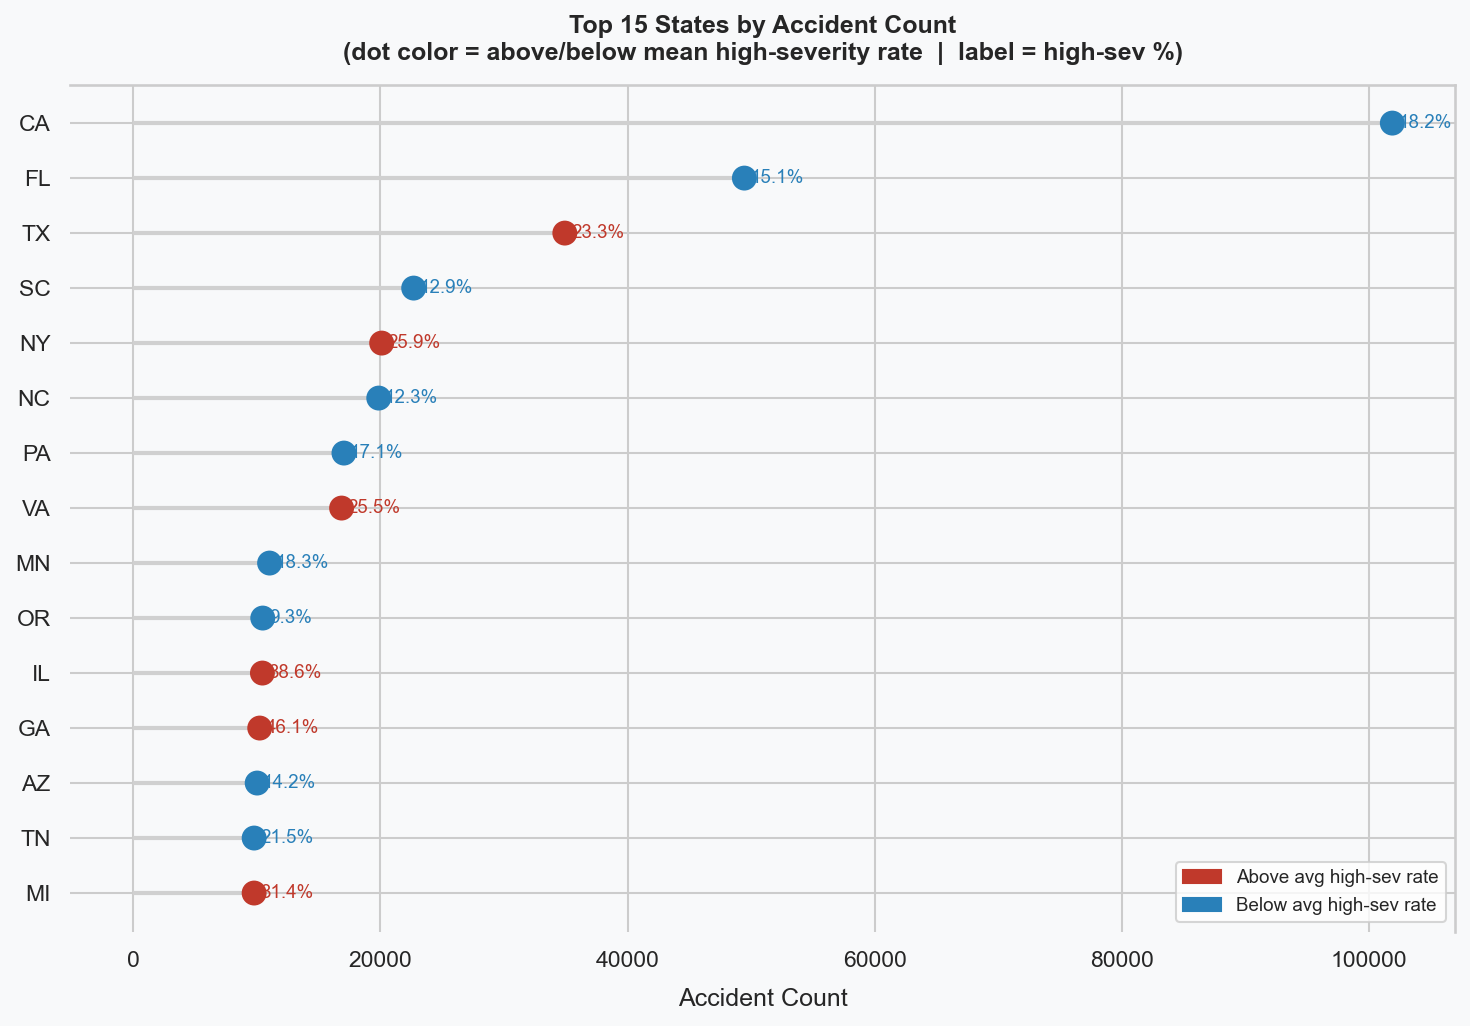

In [3]:
state_stats = df.groupby('State').agg(
    Count=('ID','count'),
    High_Sev_Rate=('Is_High_Sev','mean')
).nlargest(15,'Count').sort_values('Count')

fig, ax = plt.subplots(figsize=(10, 7))
fig.patch.set_facecolor(CLR_BG)
ax.set_facecolor(CLR_BG)

colors = [CLR_HIGH if r > state_stats['High_Sev_Rate'].mean() else CLR_LOW
          for r in state_stats['High_Sev_Rate']]

ax.hlines(y=state_stats.index, xmin=0, xmax=state_stats['Count'],
          color='#d0d0d0', linewidth=2, zorder=1)
ax.scatter(state_stats['Count'], state_stats.index,
           color=colors, s=120, zorder=3)

for state, row in state_stats.iterrows():
    ax.text(row['Count']+500, state,
            f"{row['High_Sev_Rate']*100:.1f}%",
            va='center', fontsize=9,
            color=CLR_HIGH if row['High_Sev_Rate'] > state_stats['High_Sev_Rate'].mean() else CLR_LOW)

ax.set_xlabel('Accident Count', labelpad=8)
ax.set_title('Top 15 States by Accident Count\n(dot color = above/below mean high-severity rate  |  label = high-sev %)', pad=12)
handles = [mpatches.Patch(color=CLR_HIGH, label='Above avg high-sev rate'),
           mpatches.Patch(color=CLR_LOW,  label='Below avg high-sev rate')]
ax.legend(handles=handles, loc='lower right', fontsize=9)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
plt.tight_layout()
save('chart_O1_state_lollipop'); plt.show()

### Chart O-2 | Year Trend — Stacked Area + Severity Rate Line

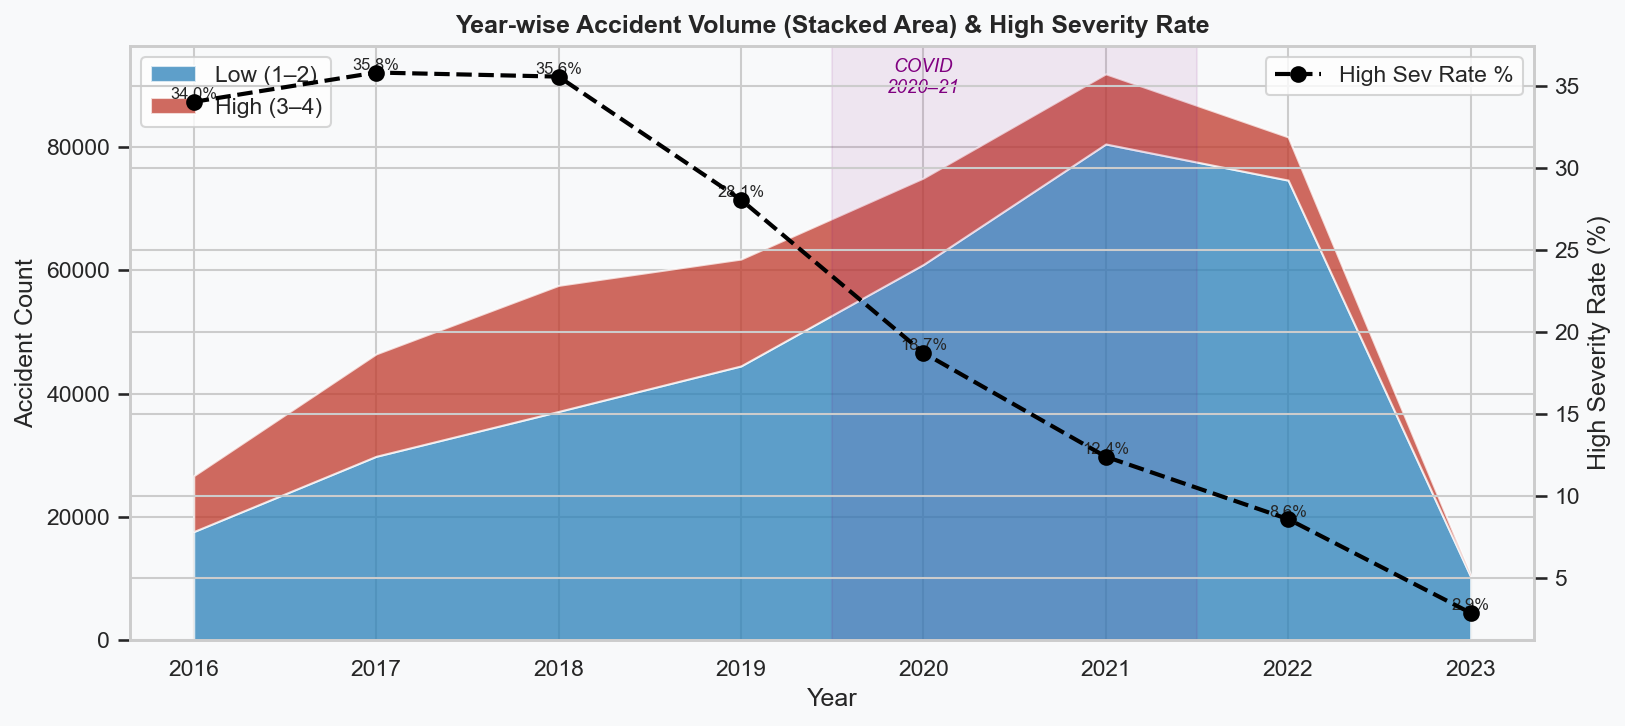

In [4]:
yr = df.groupby(['Year','Severity_Group']).size().unstack(fill_value=0)
yr_rate = (yr.get('High (3–4)',0) / yr.sum(axis=1) * 100)

fig, ax1 = plt.subplots(figsize=(11, 5))
ax2 = ax1.twinx()
fig.patch.set_facecolor(CLR_BG); ax1.set_facecolor(CLR_BG)

x = yr.index.tolist()
ax1.stackplot(x, yr.get('Low (1–2)',0), yr.get('High (3–4)',0),
              labels=['Low (1–2)','High (3–4)'],
              colors=[CLR_LOW, CLR_HIGH], alpha=0.75)
ax2.plot(x, yr_rate, 'o--', color='black', lw=2, ms=7, label='High Sev Rate %', zorder=5)

# COVID band
ax1.axvspan(2019.5, 2021.5, alpha=0.08, color='purple')
ax1.text(2020, ax1.get_ylim()[1]*0.92, 'COVID\n2020–21',
         color='purple', fontsize=9, style='italic', ha='center')

for xi, yi in zip(x, yr_rate):
    ax2.annotate(f'{yi:.1f}%', (xi, yi+0.15), ha='center', fontsize=8)

ax1.set_xlabel('Year'); ax1.set_ylabel('Accident Count')
ax2.set_ylabel('High Severity Rate (%)')
ax1.legend(loc='upper left'); ax2.legend(loc='upper right')
ax1.set_title('Year-wise Accident Volume (Stacked Area) & High Severity Rate')
plt.tight_layout()
save('chart_O2_year_area'); plt.show()

---
## Hypothesis 1 — Bad Weather → Higher Severity

### Chart H1-1 | Diverging Bar — Deviation from Mean High-Severity Rate

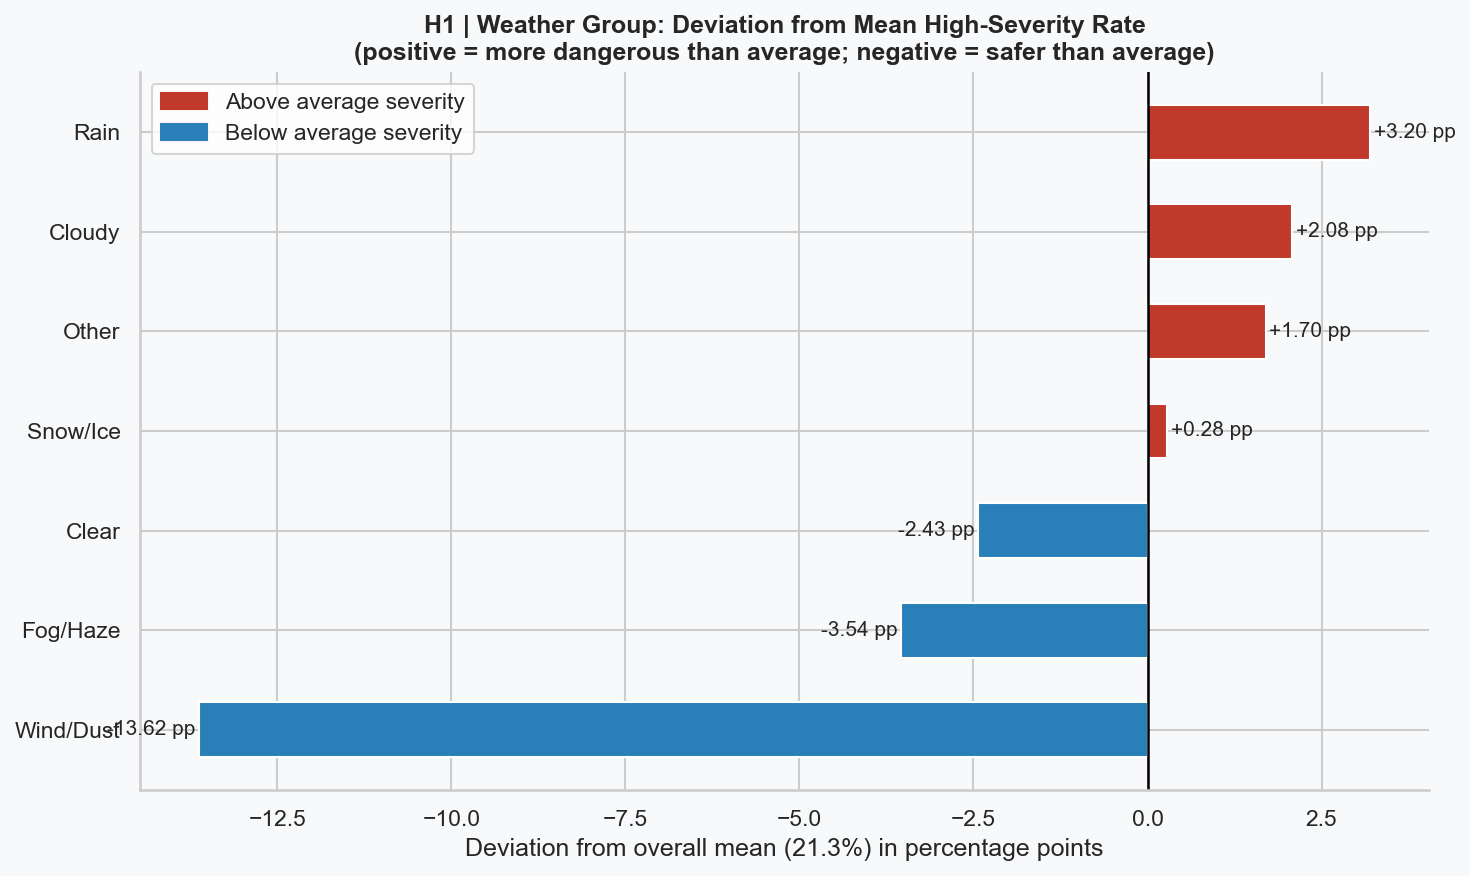

In [5]:
# Each bar shows how much a weather group deviates from the overall mean
overall_rate = df['Is_High_Sev'].mean() * 100
wg = df.groupby('Weather_Group')['Is_High_Sev'].mean() * 100
wg = wg.reindex(WEATHER_ORDER).dropna()
deviation = (wg - overall_rate).sort_values()

colors = [CLR_HIGH if v > 0 else CLR_LOW for v in deviation]

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(CLR_BG); ax.set_facecolor(CLR_BG)

bars = ax.barh(deviation.index, deviation.values,
               color=colors, edgecolor='white', height=0.55)
ax.axvline(0, color='black', linewidth=1.2, linestyle='-')

for bar, val in zip(bars, deviation.values):
    x_pos = val + (0.05 if val >= 0 else -0.05)
    ha = 'left' if val >= 0 else 'right'
    ax.text(x_pos, bar.get_y()+bar.get_height()/2,
            f'{val:+.2f} pp', va='center', ha=ha, fontsize=10)

ax.set_xlabel(f'Deviation from overall mean ({overall_rate:.1f}%) in percentage points')
ax.set_title('H1 | Weather Group: Deviation from Mean High-Severity Rate\n'
             '(positive = more dangerous than average; negative = safer than average)')
handles = [mpatches.Patch(color=CLR_HIGH, label='Above average severity'),
           mpatches.Patch(color=CLR_LOW,  label='Below average severity')]
ax.legend(handles=handles)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
save('chart_H1_1_diverging_bar'); plt.show()

### Chart H1-2 | Violin Plot — Visibility Distribution by Severity & Weather

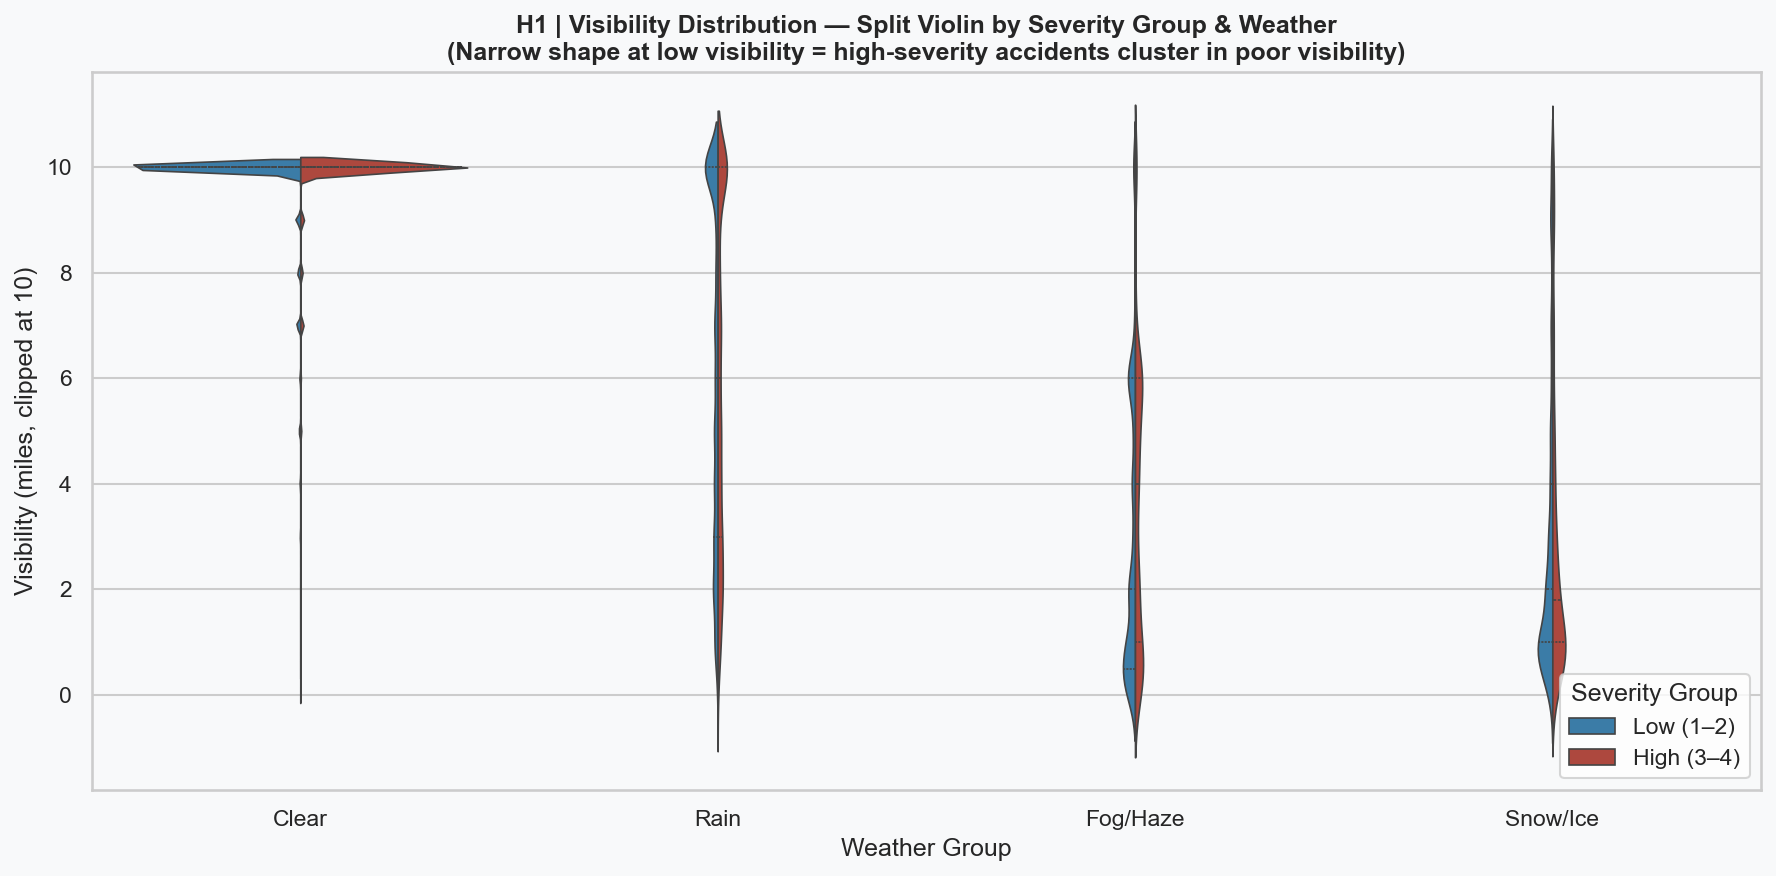

In [6]:
# Focus on the most impactful weather groups
focus = df[df['Weather_Group'].isin(['Clear','Rain','Fog/Haze','Snow/Ice'])].copy()
focus_clip = focus[focus['Visibility(mi)'] <= 10]

fig, ax = plt.subplots(figsize=(12, 6))
fig.patch.set_facecolor(CLR_BG); ax.set_facecolor(CLR_BG)

palette = {'Low (1–2)': CLR_LOW, 'High (3–4)': CLR_HIGH}
sns.violinplot(
    data=focus_clip, x='Weather_Group', y='Visibility(mi)',
    hue='Severity_Group', palette=palette,
    split=True, inner='quartile',
    order=['Clear','Rain','Fog/Haze','Snow/Ice'],
    hue_order=['Low (1–2)','High (3–4)'],
    linewidth=0.8, ax=ax
)
ax.set_xlabel('Weather Group'); ax.set_ylabel('Visibility (miles, clipped at 10)')
ax.set_title('H1 | Visibility Distribution — Split Violin by Severity Group & Weather\n'
             '(Narrow shape at low visibility = high-severity accidents cluster in poor visibility)')
ax.legend(title='Severity Group', loc='lower right')
plt.tight_layout()
save('chart_H1_2_violin_visibility'); plt.show()

### Chart H1-3 | KDE Plot — Temperature Distribution by Severity Group

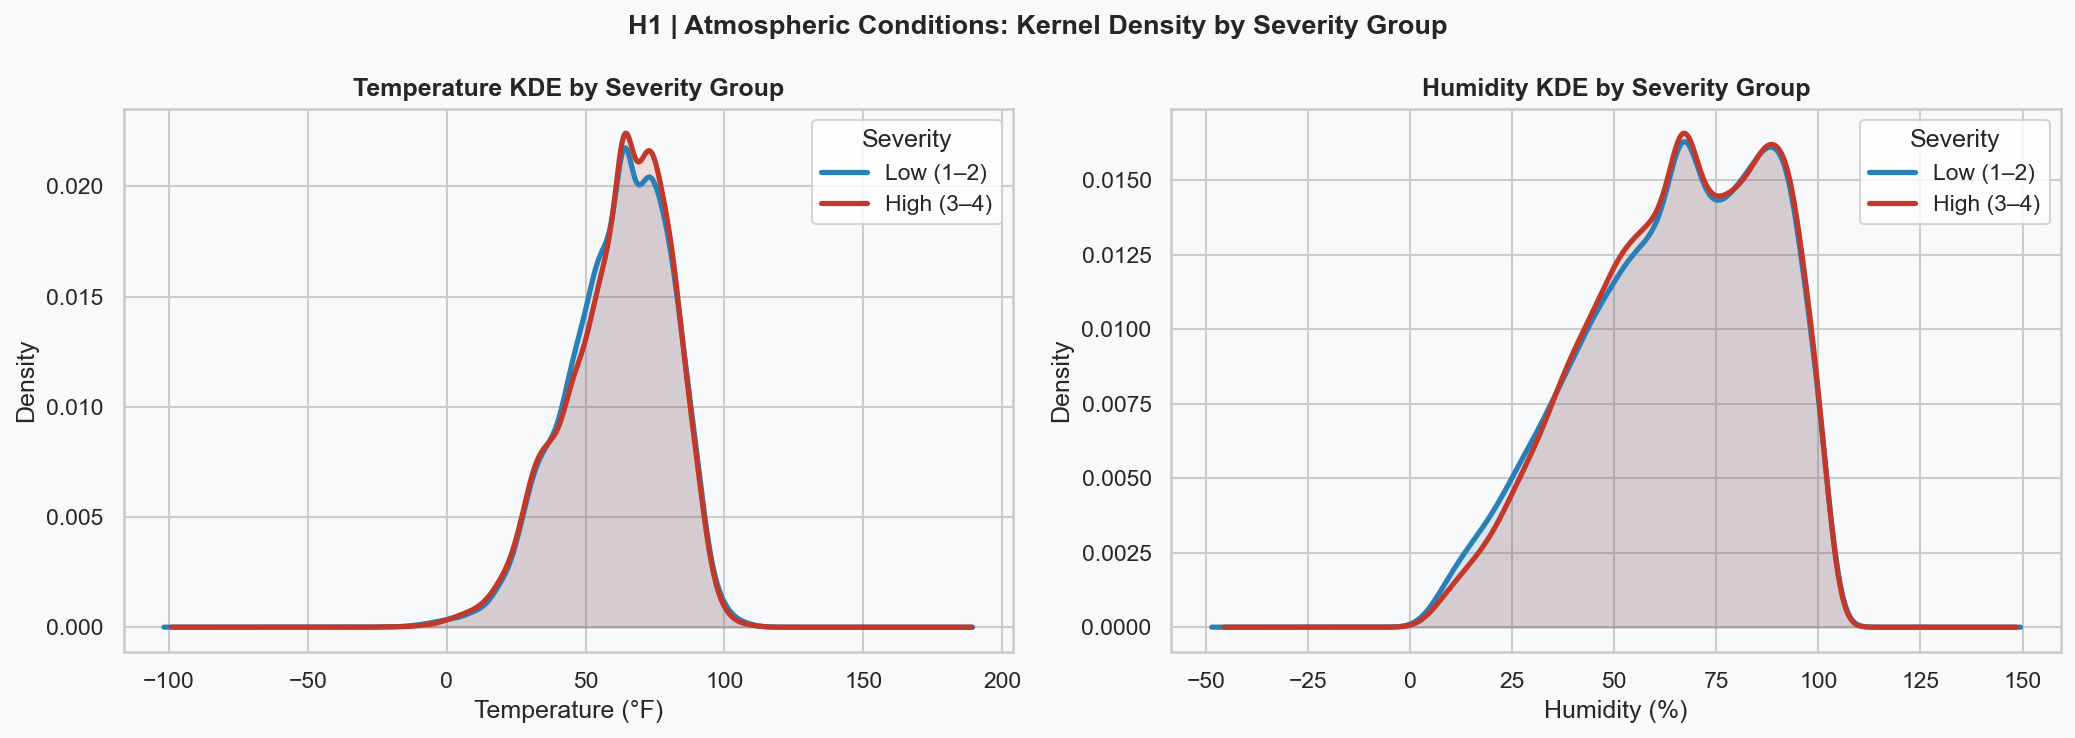

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)
fig.patch.set_facecolor(CLR_BG)

# Left — KDE of Temperature
for grp, clr in [('Low (1–2)', CLR_LOW), ('High (3–4)', CLR_HIGH)]:
    subset = df[df['Severity_Group']==grp]['Temperature(F)']
    subset.plot.kde(ax=axes[0], color=clr, linewidth=2.5, label=grp, bw_method=0.15)
    axes[0].fill_between(
        axes[0].lines[-1].get_xdata(),
        axes[0].lines[-1].get_ydata(),
        alpha=0.15, color=clr
    )

axes[0].set_xlabel('Temperature (°F)')
axes[0].set_ylabel('Density')
axes[0].set_title('Temperature KDE by Severity Group')
axes[0].legend(title='Severity')
axes[0].set_facecolor(CLR_BG)

# Right — KDE of Humidity
for grp, clr in [('Low (1–2)', CLR_LOW), ('High (3–4)', CLR_HIGH)]:
    subset = df[df['Severity_Group']==grp]['Humidity(%)']
    subset.plot.kde(ax=axes[1], color=clr, linewidth=2.5, label=grp, bw_method=0.15)
    axes[1].fill_between(
        axes[1].lines[-1].get_xdata(),
        axes[1].lines[-1].get_ydata(),
        alpha=0.15, color=clr
    )

axes[1].set_xlabel('Humidity (%)')
axes[1].set_ylabel('Density')
axes[1].set_title('Humidity KDE by Severity Group')
axes[1].legend(title='Severity')
axes[1].set_facecolor(CLR_BG)

fig.suptitle('H1 | Atmospheric Conditions: Kernel Density by Severity Group',
             fontsize=13, fontweight='bold')
plt.tight_layout()
save('chart_H1_3_kde_temp_humid'); plt.show()

### Chart H1-4 | Slope Chart — High Severity Rate: Day vs Night by Weather Group

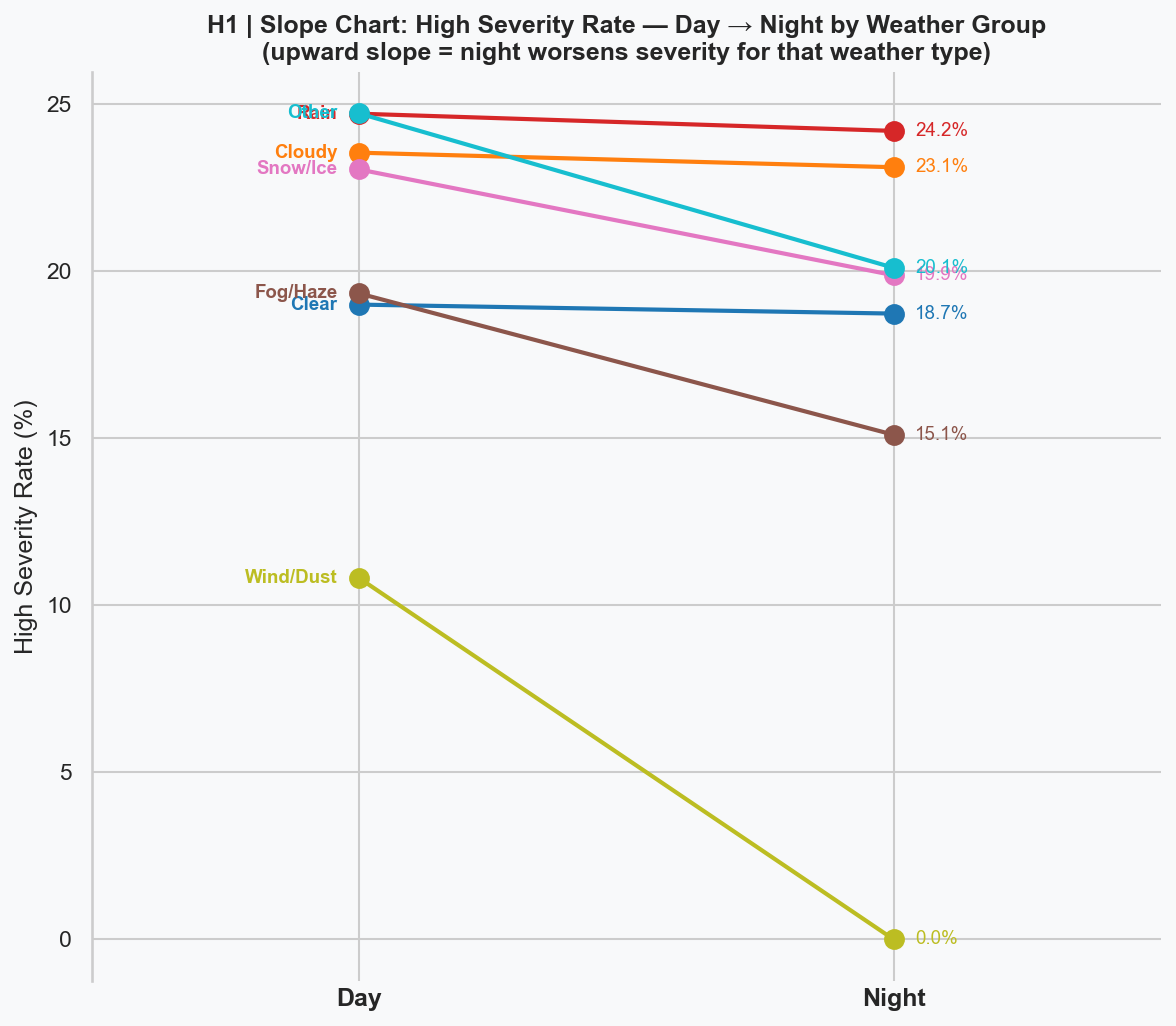

In [9]:
dn = df[df['Sunrise_Sunset'].isin(['Day','Night'])].copy()
slope = dn.groupby(['Weather_Group','Sunrise_Sunset'])['Is_High_Sev'].mean()*100
slope = slope.unstack().reindex(WEATHER_ORDER).dropna()

fig, ax = plt.subplots(figsize=(8, 7))
fig.patch.set_facecolor(CLR_BG); ax.set_facecolor(CLR_BG)

cmap = plt.cm.get_cmap('tab10', len(slope))

for i, (weather, row) in enumerate(slope.iterrows()):
    clr = cmap(i)
    ax.plot([0, 1], [row['Day'], row['Night']], 'o-',
            color=clr, linewidth=2, markersize=9, label=weather)
    ax.text(-0.04, row['Day'], weather, ha='right', va='center',
            fontsize=9, color=clr, fontweight='bold')
    ax.text(1.04, row['Night'], f"{row['Night']:.1f}%", ha='left', va='center',
            fontsize=9, color=clr)

ax.set_xlim(-0.5, 1.5)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Day', 'Night'], fontsize=12, fontweight='bold')
ax.set_ylabel('High Severity Rate (%)')
ax.set_title('H1 | Slope Chart: High Severity Rate — Day → Night by Weather Group\n'
             '(upward slope = night worsens severity for that weather type)')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.tick_params(axis='x', which='both', length=0)
plt.tight_layout()
save('chart_H1_4_slope_day_night'); plt.show()

### Chart H1-5 | Bubble Chart — Weather: Volume × Visibility × Severity Rate

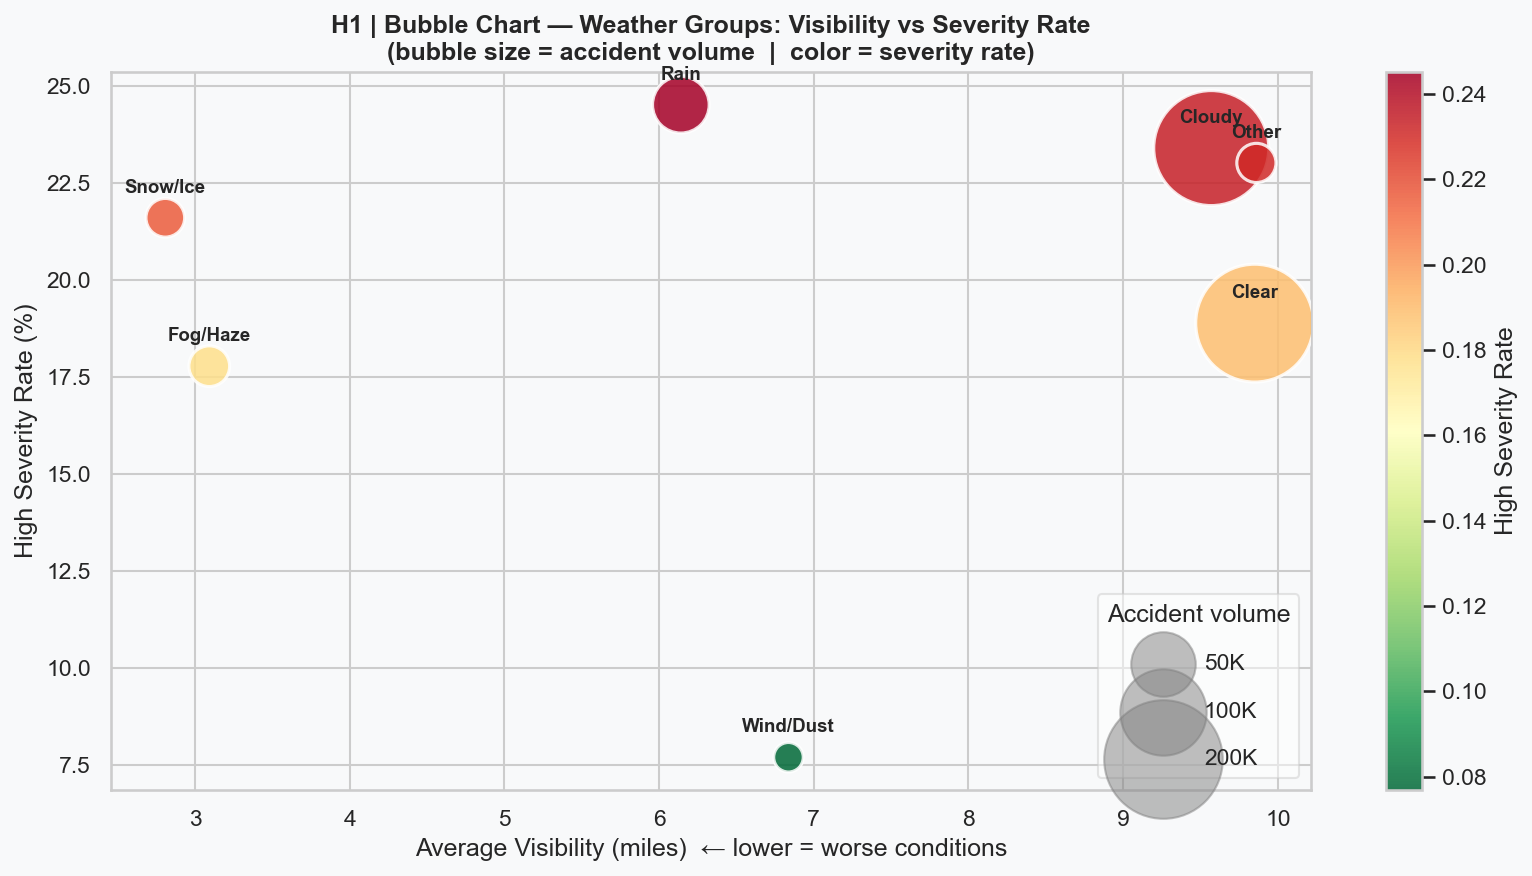

In [10]:
bubble = df.groupby('Weather_Group').agg(
    Count=('ID','count'),
    Avg_Visibility=('Visibility(mi)','mean'),
    High_Sev_Rate=('Is_High_Sev','mean')
).reindex(WEATHER_ORDER).dropna()

norm  = mcolors.Normalize(vmin=bubble['High_Sev_Rate'].min(),
                           vmax=bubble['High_Sev_Rate'].max())
cmap  = plt.cm.RdYlGn_r
sizes = (bubble['Count'] / bubble['Count'].max()) * 3000 + 200

fig, ax = plt.subplots(figsize=(11, 6))
fig.patch.set_facecolor(CLR_BG); ax.set_facecolor(CLR_BG)

sc = ax.scatter(
    bubble['Avg_Visibility'], bubble['High_Sev_Rate']*100,
    s=sizes, c=bubble['High_Sev_Rate'], cmap=cmap, norm=norm,
    alpha=0.85, edgecolors='white', linewidth=1.5, zorder=3
)
for wg, row in bubble.iterrows():
    ax.annotate(wg,
                (row['Avg_Visibility'], row['High_Sev_Rate']*100),
                textcoords='offset points', xytext=(0, 12),
                ha='center', fontsize=9, fontweight='bold')

plt.colorbar(sc, ax=ax, label='High Severity Rate')
ax.set_xlabel('Average Visibility (miles)  ← lower = worse conditions')
ax.set_ylabel('High Severity Rate (%)')
ax.set_title('H1 | Bubble Chart — Weather Groups: Visibility vs Severity Rate\n'
             '(bubble size = accident volume  |  color = severity rate)')

# size legend
for n_k, label in [(50000,'50K'),(100000,'100K'),(200000,'200K')]:
    ax.scatter([], [], s=(n_k/bubble['Count'].max())*3000+200,
               color='grey', alpha=0.5, label=label)
ax.legend(title='Accident volume', scatterpoints=1, labelspacing=1.2,
          loc='lower right', framealpha=0.5)
plt.tight_layout()
save('chart_H1_5_bubble_weather'); plt.show()

---
## Hypothesis 2 — Rush Hours → Higher Severity

### Chart H2-1 | Polar Clock — Accident Volume by Hour

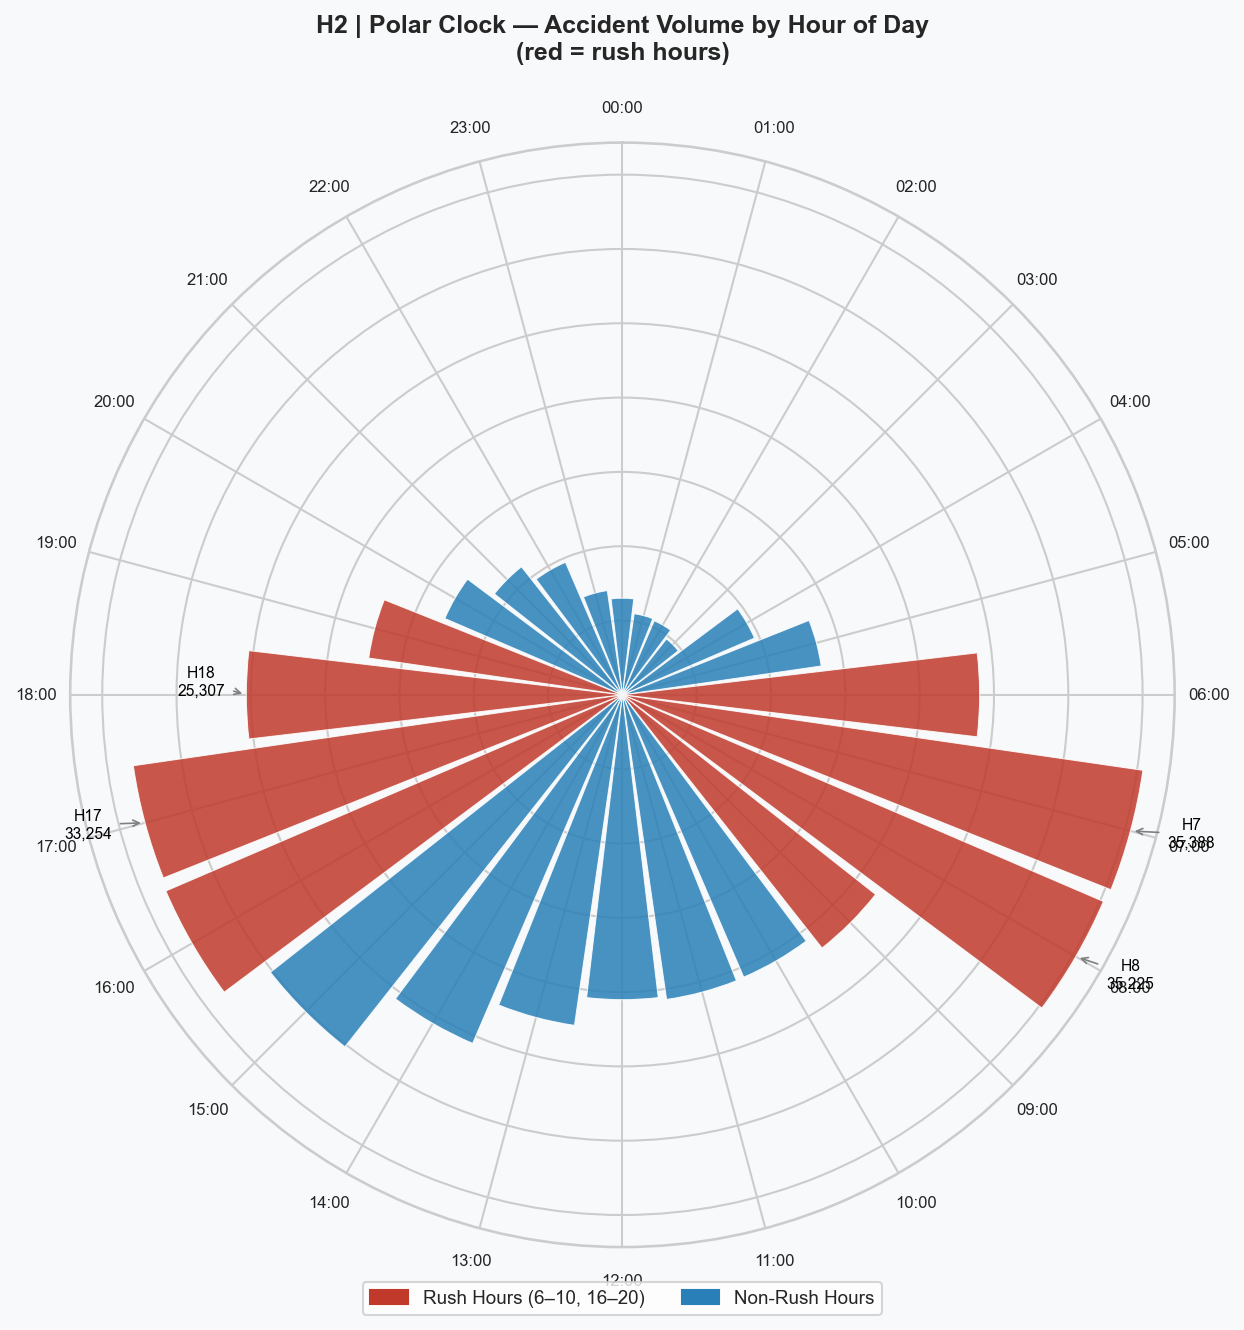

In [11]:
hourly = df.groupby('Hour').agg(
    Count=('ID','count'),
    High_Sev_Rate=('Is_High_Sev','mean')
)

theta  = np.linspace(0, 2*np.pi, 24, endpoint=False)
width  = 2*np.pi / 24 * 0.9
radii  = hourly['Count'].values
is_rush= np.array([h in list(range(6,10)) + list(range(16,20)) for h in hourly.index])
colors = np.where(is_rush, CLR_HIGH, CLR_LOW)

fig = plt.figure(figsize=(9, 9))
fig.patch.set_facecolor(CLR_BG)
ax  = fig.add_subplot(111, polar=True)
ax.set_facecolor(CLR_BG)

# start at top (midnight) and go clockwise
ax.set_theta_zero_location('N')
ax.set_theta_direction(-1)

bars = ax.bar(theta, radii, width=width, bottom=0,
              color=colors, alpha=0.85, edgecolor='white', linewidth=0.5)

ax.set_xticks(theta)
ax.set_xticklabels([f'{h:02d}:00' for h in range(24)], fontsize=8)
ax.set_yticklabels([])
ax.set_title('H2 | Polar Clock — Accident Volume by Hour of Day\n'
             '(red = rush hours)', pad=20, fontsize=12, fontweight='bold')

# annotate peak hours
for h in [7, 8, 17, 18]:
    t = theta[h]
    r = radii[h]
    ax.annotate(f'H{h}\n{r:,}',
                xy=(t, r), xytext=(t, r*1.12),
                fontsize=7.5, ha='center', color='black',
                arrowprops=dict(arrowstyle='->', color='grey', lw=0.8))

handles = [mpatches.Patch(color=CLR_HIGH, label='Rush Hours (6–10, 16–20)'),
           mpatches.Patch(color=CLR_LOW,  label='Non-Rush Hours')]
ax.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, -0.07),
          ncol=2, fontsize=9)
plt.tight_layout()
save('chart_H2_1_polar_clock'); plt.show()

### Chart H2-2 | Ridgeline (Joy) Plot — Severity Score Distribution by Time Bucket

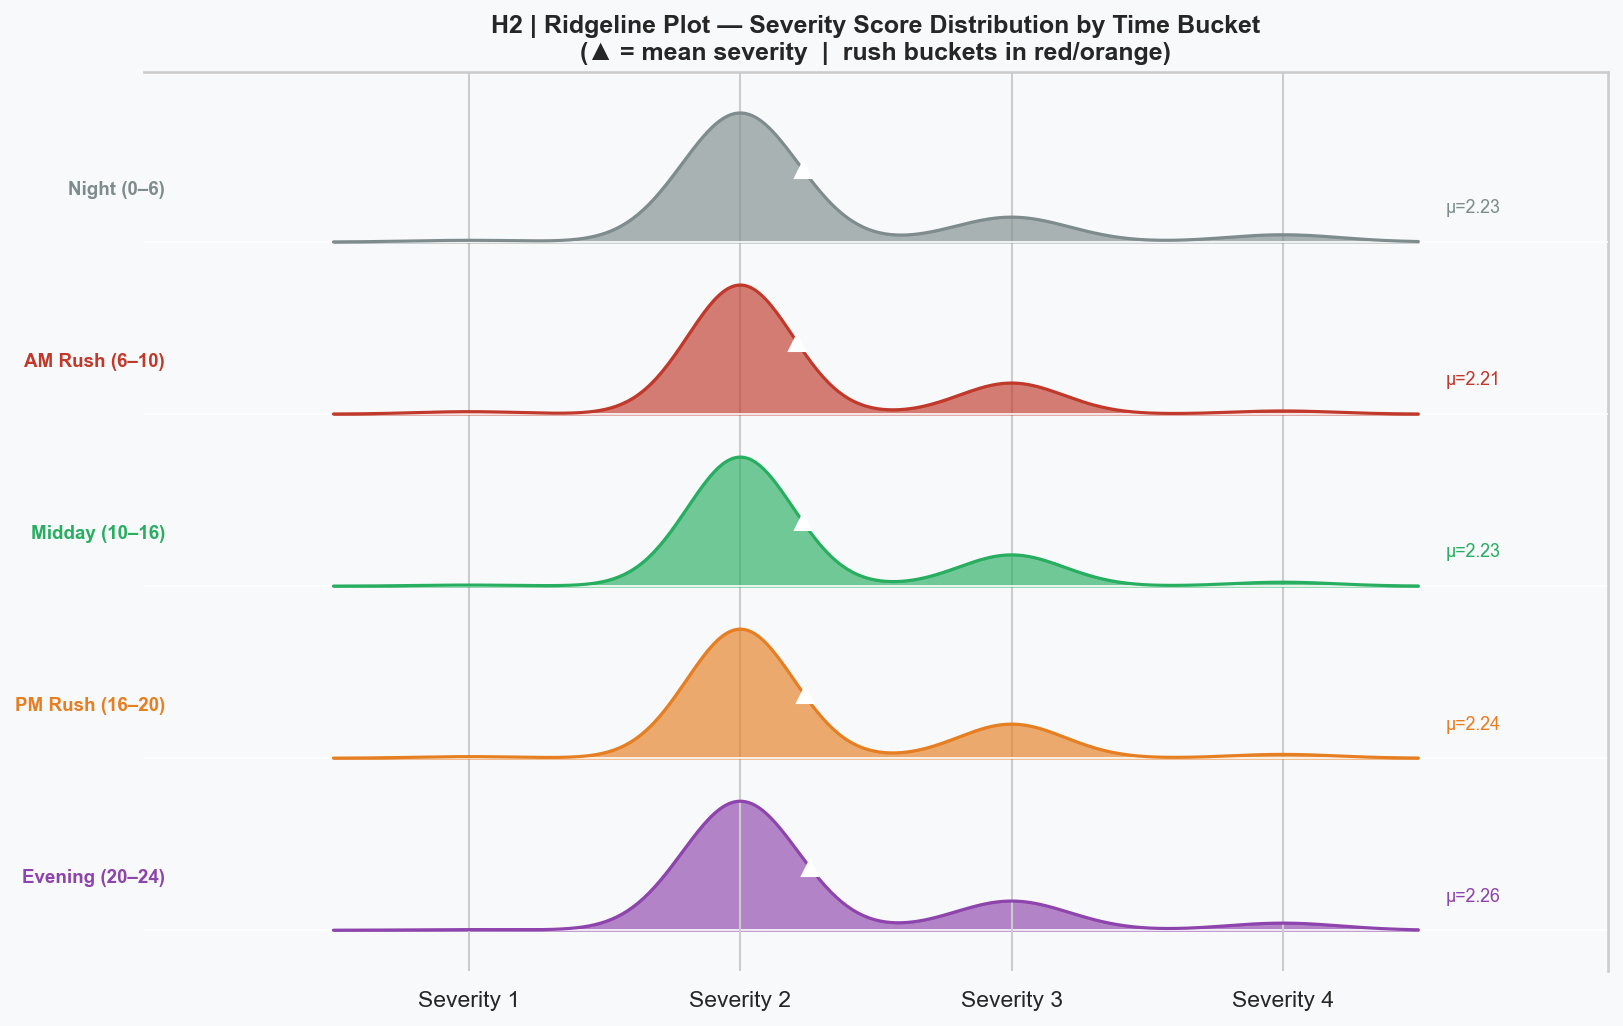

In [12]:
# Ridgeline using overlapping KDE areas — one row per time bucket
from scipy.stats import gaussian_kde

x_vals   = np.linspace(0.5, 4.5, 400)
spacing  = 1.2
bucket_colors = {
    'Night (0–6)'   : '#7f8c8d',
    'AM Rush (6–10)': CLR_HIGH,
    'Midday (10–16)': '#27ae60',
    'PM Rush (16–20)': CLR_ACCENT,
    'Evening (20–24)': '#8e44ad'
}

fig, ax = plt.subplots(figsize=(11, 7))
fig.patch.set_facecolor(CLR_BG); ax.set_facecolor(CLR_BG)

for i, bucket in enumerate(reversed(BUCKET_ORDER)):
    data = df[df['Time_Bucket']==bucket]['Severity'].values
    if len(data) < 10: continue
    kde  = gaussian_kde(data, bw_method=0.4)
    y    = kde(x_vals)
    y_norm = y / y.max() * 0.9
    baseline = i * spacing
    clr  = bucket_colors[bucket]
    ax.fill_between(x_vals, baseline, baseline + y_norm,
                    color=clr, alpha=0.65, zorder=i)
    ax.plot(x_vals, baseline + y_norm, color=clr, linewidth=1.5, zorder=i+1)
    ax.axhline(baseline, color='white', linewidth=0.8, zorder=i)

    # mean marker
    mean_sev = data.mean()
    mean_y   = kde(mean_sev)[0]/y.max()*0.9 + baseline
    ax.plot(mean_sev, mean_y, 'w^', ms=8, zorder=i+2)
    ax.text(-0.12, baseline + 0.3, bucket, ha='right', va='bottom',
            fontsize=9, color=clr, fontweight='bold')
    ax.text(4.6, baseline + 0.2, f'μ={mean_sev:.2f}', ha='left',
            fontsize=8.5, color=clr)

ax.set_xlim(-0.2, 5.2)
ax.set_xticks([1,2,3,4])
ax.set_xticklabels(['Severity 1','Severity 2','Severity 3','Severity 4'])
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.set_title('H2 | Ridgeline Plot — Severity Score Distribution by Time Bucket\n'
             '(▲ = mean severity  |  rush buckets in red/orange)')
plt.tight_layout()
save('chart_H2_2_ridgeline'); plt.show()

### Chart H2-3 | Bump Chart — Hourly High-Severity Rank: Weekday vs Weekend

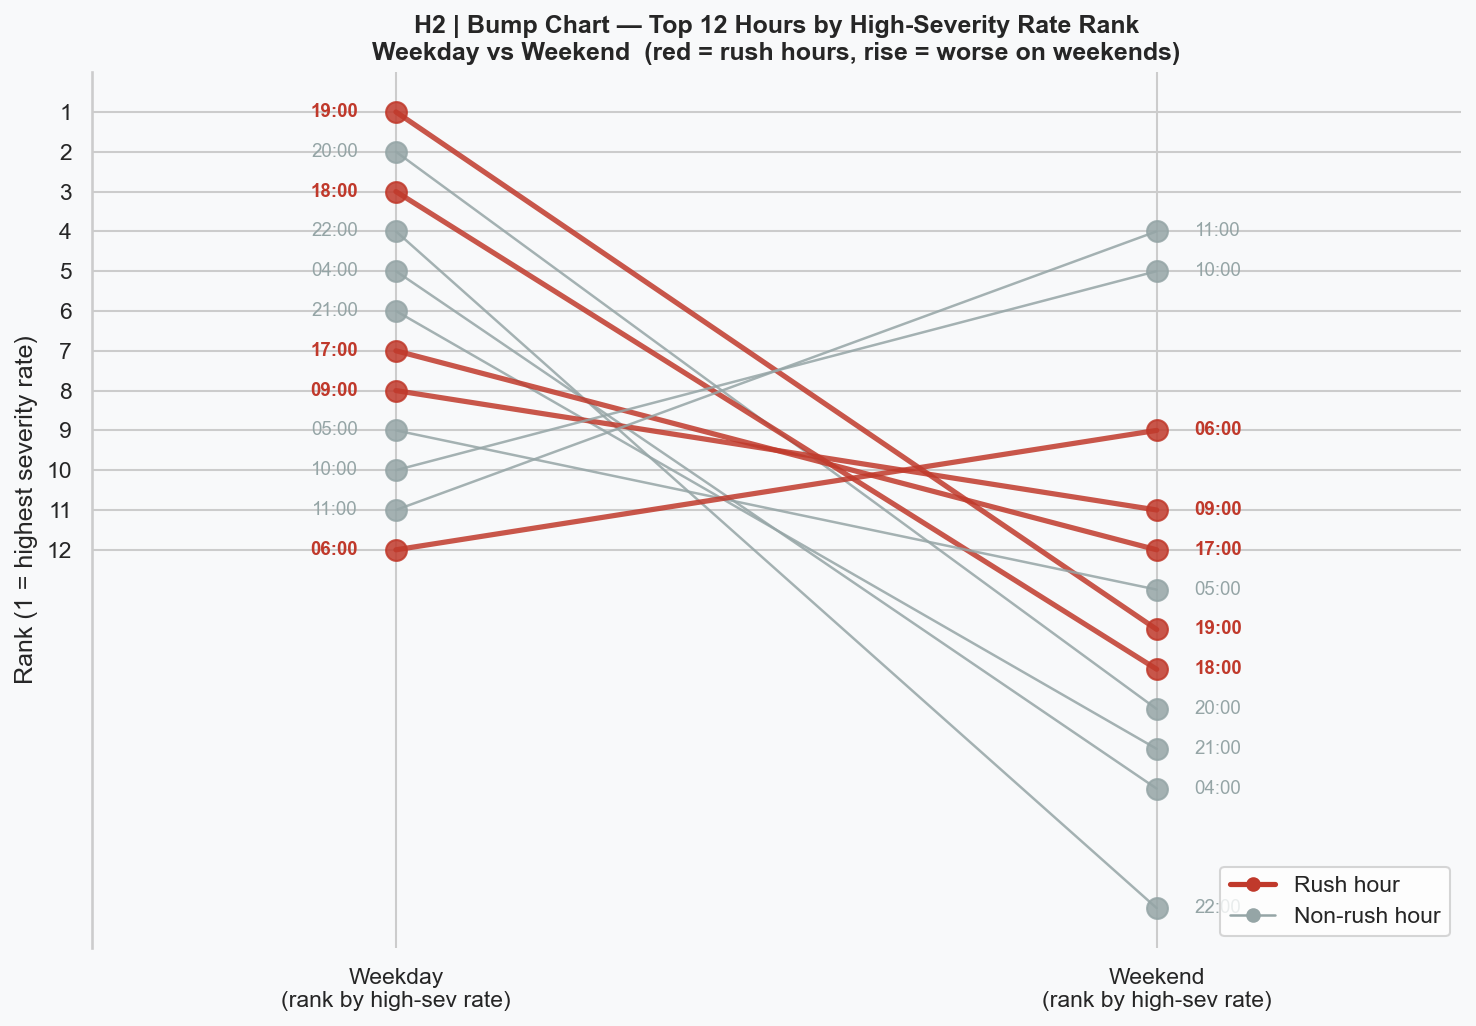

In [13]:
hr_wkd = df.groupby(['Hour','Is_Weekend'])['Is_High_Sev'].mean().unstack()
hr_wkd.columns = ['Weekday','Weekend']
hr_wkd['Weekday_Rank'] = hr_wkd['Weekday'].rank(ascending=False).astype(int)
hr_wkd['Weekend_Rank'] = hr_wkd['Weekend'].rank(ascending=False).astype(int)

# show only top-12 hours by weekday rank for clarity
top12 = hr_wkd.nsmallest(12, 'Weekday_Rank').index.tolist()
bump  = hr_wkd.loc[top12].sort_values('Weekday_Rank')

fig, ax = plt.subplots(figsize=(10, 7))
fig.patch.set_facecolor(CLR_BG); ax.set_facecolor(CLR_BG)

rush_hours = set(range(6,10)) | set(range(16,20))

for h, row in bump.iterrows():
    clr = CLR_HIGH if h in rush_hours else CLR_NEUTRAL
    lw  = 2.5 if h in rush_hours else 1.2
    ax.plot([0,1], [row['Weekday_Rank'], row['Weekend_Rank']],
            'o-', color=clr, linewidth=lw, markersize=10, alpha=0.85)
    ax.text(-0.05, row['Weekday_Rank'], f'{h:02d}:00', ha='right',
            va='center', fontsize=9, color=clr, fontweight='bold' if h in rush_hours else 'normal')
    ax.text(1.05, row['Weekend_Rank'], f'{h:02d}:00', ha='left',
            va='center', fontsize=9, color=clr, fontweight='bold' if h in rush_hours else 'normal')

ax.set_xlim(-0.4, 1.4)
ax.set_xticks([0,1])
ax.set_xticklabels(['Weekday\n(rank by high-sev rate)','Weekend\n(rank by high-sev rate)'],
                   fontsize=11)
ax.invert_yaxis()
ax.set_ylabel('Rank (1 = highest severity rate)')
ax.set_yticks(range(1,13))
ax.set_title('H2 | Bump Chart — Top 12 Hours by High-Severity Rate Rank\n'
             'Weekday vs Weekend  (red = rush hours, rise = worse on weekends)')
handles = [Line2D([0],[0], color=CLR_HIGH, lw=2.5, marker='o', label='Rush hour'),
           Line2D([0],[0], color=CLR_NEUTRAL, lw=1.2, marker='o', label='Non-rush hour')]
ax.legend(handles=handles, loc='lower right')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
plt.tight_layout()
save('chart_H2_3_bump_chart'); plt.show()

### Chart H2-4 | Dot Strip Plot — Accident Duration by Time Bucket × Severity

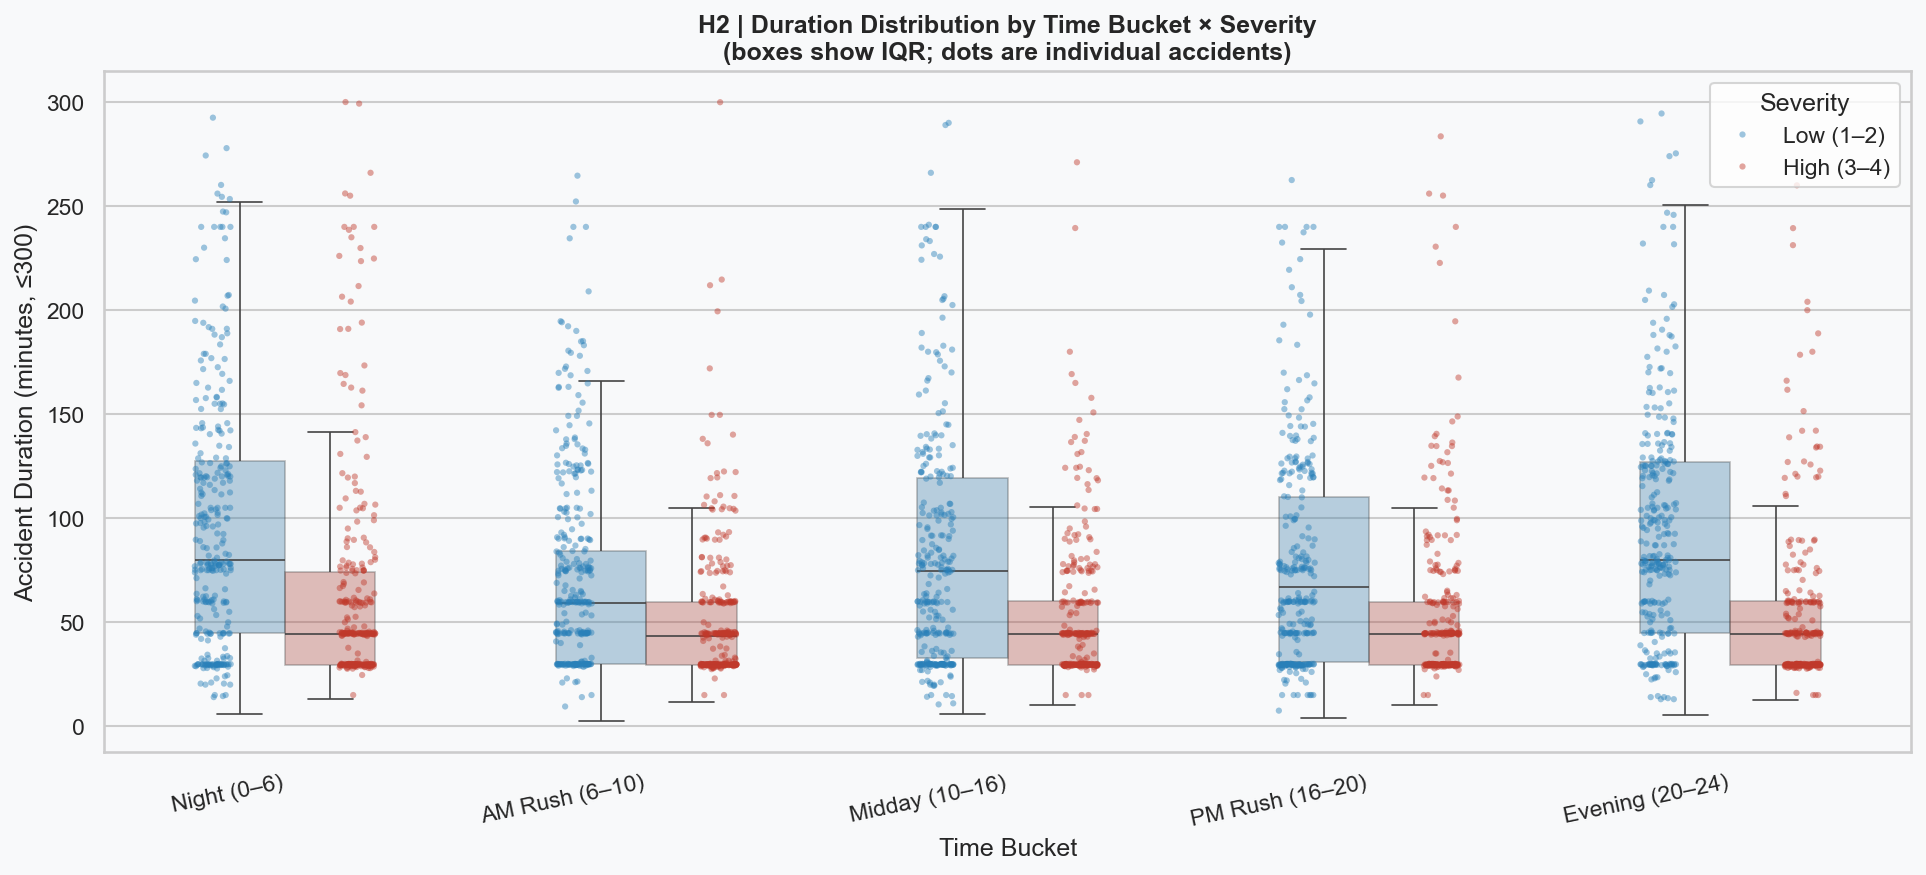

In [14]:
dur_df = df.dropna(subset=['Duration_Min']).copy()
dur_df = dur_df[dur_df['Duration_Min'] <= 300]   # clip at 5 hrs for readability

# sample for stripplot performance
sample = dur_df.groupby(['Time_Bucket','Severity_Group'], group_keys=False).apply(
    lambda g: g.sample(min(len(g), 300), random_state=42)
)

fig, ax = plt.subplots(figsize=(13, 6))
fig.patch.set_facecolor(CLR_BG); ax.set_facecolor(CLR_BG)

# boxplot underneath for context
sns.boxplot(data=dur_df, x='Time_Bucket', y='Duration_Min',
            hue='Severity_Group',
            palette={'Low (1–2)': CLR_LOW, 'High (3–4)': CLR_HIGH},
            order=BUCKET_ORDER,
            hue_order=['Low (1–2)','High (3–4)'],
            width=0.5, fliersize=0, linewidth=0.8,
            boxprops=dict(alpha=0.35), ax=ax, legend=False)

# stripplot on top
sns.stripplot(data=sample, x='Time_Bucket', y='Duration_Min',
              hue='Severity_Group',
              palette={'Low (1–2)': CLR_LOW, 'High (3–4)': CLR_HIGH},
              order=BUCKET_ORDER,
              hue_order=['Low (1–2)','High (3–4)'],
              dodge=True, size=3, alpha=0.45, jitter=True, ax=ax)

ax.set_xlabel('Time Bucket'); ax.set_ylabel('Accident Duration (minutes, ≤300)')
ax.set_xticklabels(BUCKET_ORDER, rotation=12, ha='right')
ax.set_title('H2 | Duration Distribution by Time Bucket × Severity\n'
             '(boxes show IQR; dots are individual accidents)')
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[-2:], labels[-2:], title='Severity', loc='upper right')
plt.tight_layout()
save('chart_H2_4_strip_duration'); plt.show()

### Chart H2-5 | Annotated Tile Map — High Severity Rate by Hour × Month

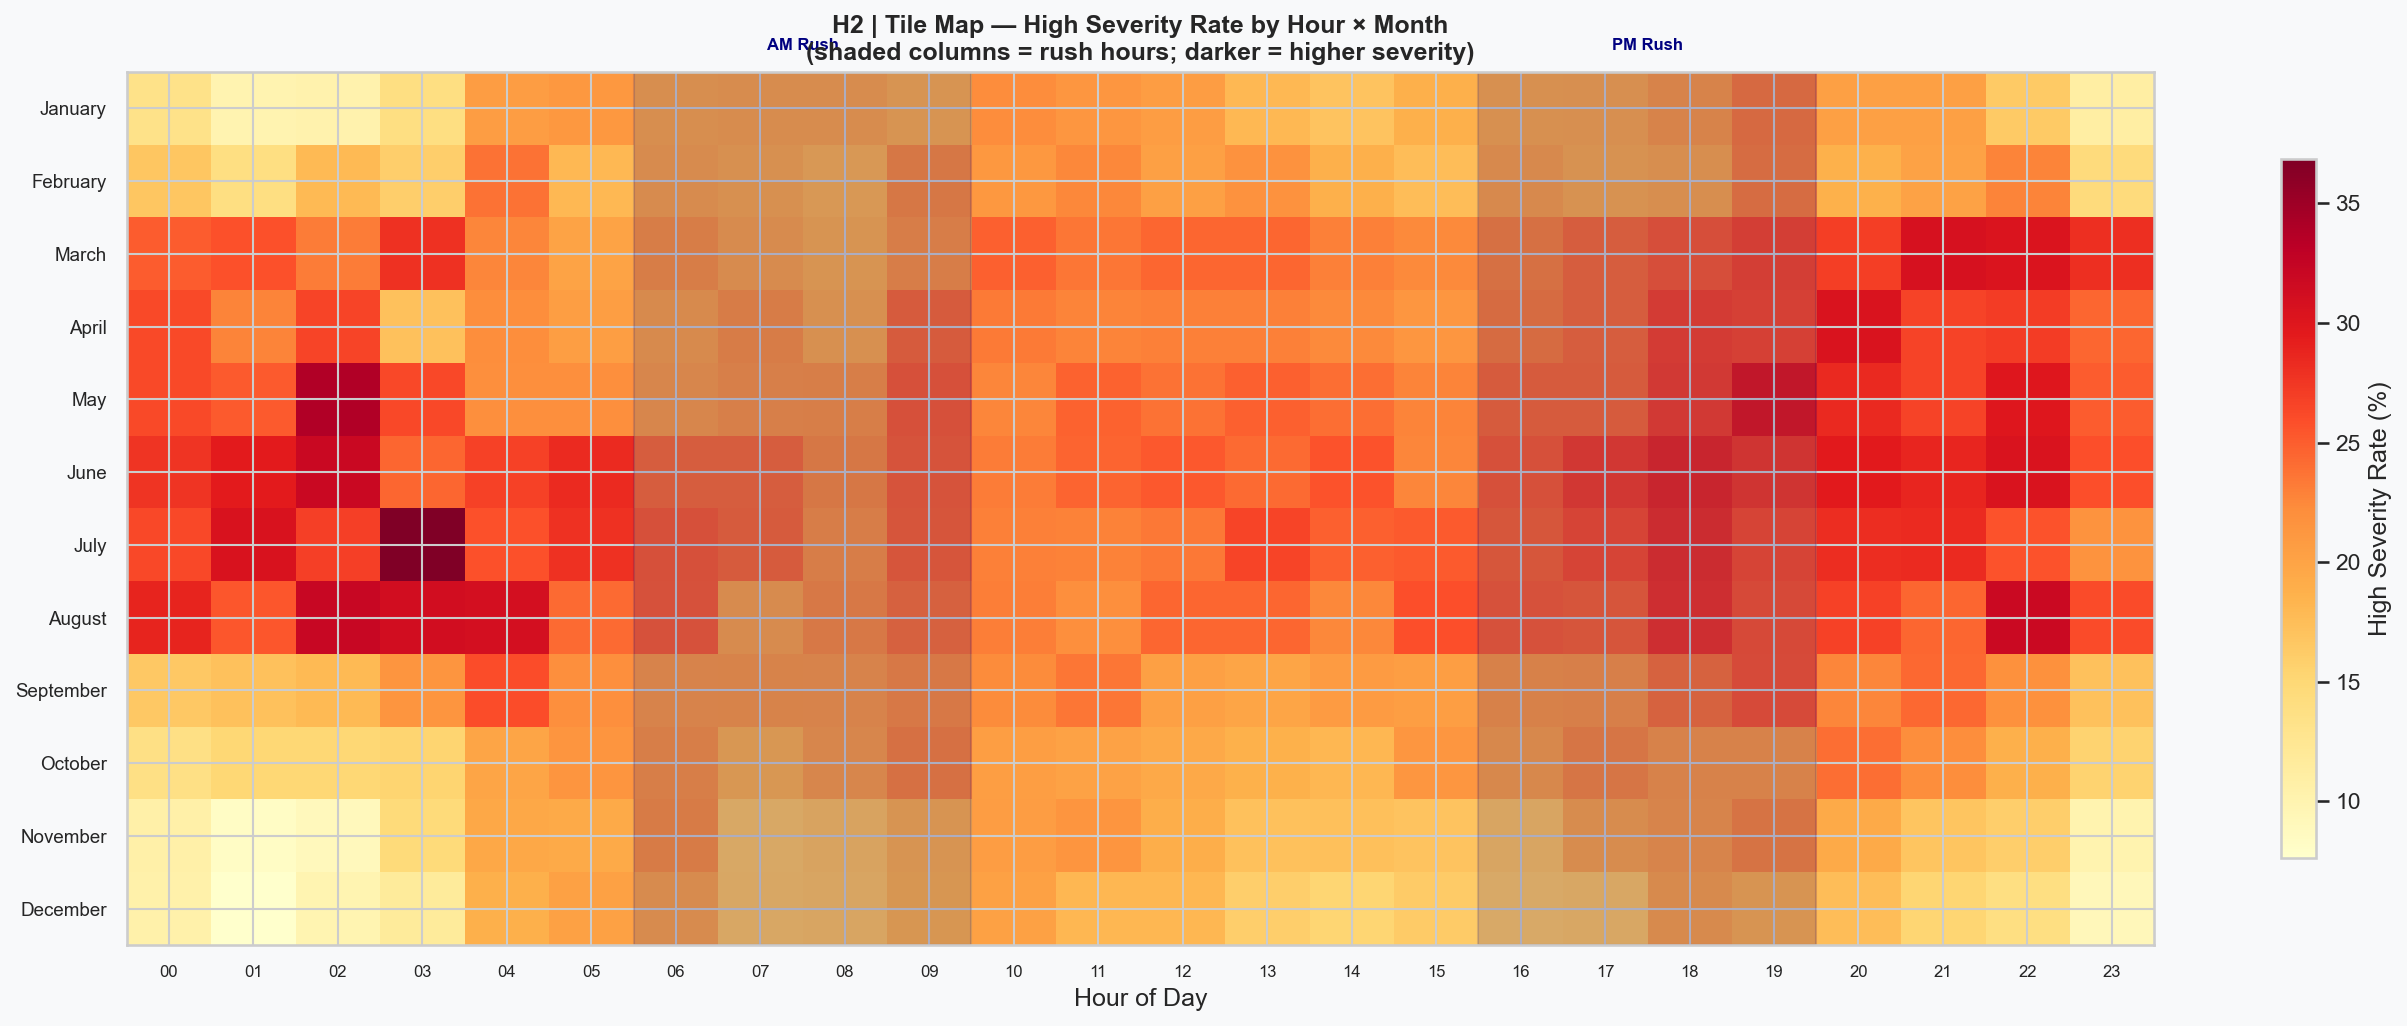

In [15]:
MONTH_ORDER = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']

tile = df.groupby(['Month','Hour'])['Is_High_Sev'].mean().unstack() * 100
tile = tile.reindex(MONTH_ORDER)

fig, ax = plt.subplots(figsize=(18, 7))
fig.patch.set_facecolor(CLR_BG)

im = ax.imshow(tile.values, aspect='auto', cmap='YlOrRd',
               vmin=tile.values.min(), vmax=tile.values.max())

ax.set_xticks(range(24))
ax.set_xticklabels([f'{h:02d}' for h in range(24)], fontsize=8)
ax.set_yticks(range(12))
ax.set_yticklabels(MONTH_ORDER, fontsize=9)

# rush hour bands
for start, end, label in [(5.5,9.5,'AM Rush'), (15.5,19.5,'PM Rush')]:
    ax.axvspan(start, end, alpha=0.15, color='navy')
    ax.text((start+end)/2, -0.8, label, ha='center', fontsize=8,
            color='navy', fontweight='bold')

plt.colorbar(im, ax=ax, label='High Severity Rate (%)', shrink=0.8)
ax.set_xlabel('Hour of Day')
ax.set_title('H2 | Tile Map — High Severity Rate by Hour × Month\n'
             '(shaded columns = rush hours; darker = higher severity)')
plt.tight_layout()
save('chart_H2_5_tile_hour_month'); plt.show()

---
## Combined — Both Hypotheses

### Chart C-1 | Bubble Matrix — Weather × Time Bucket (Size=Count, Color=Sev Rate)

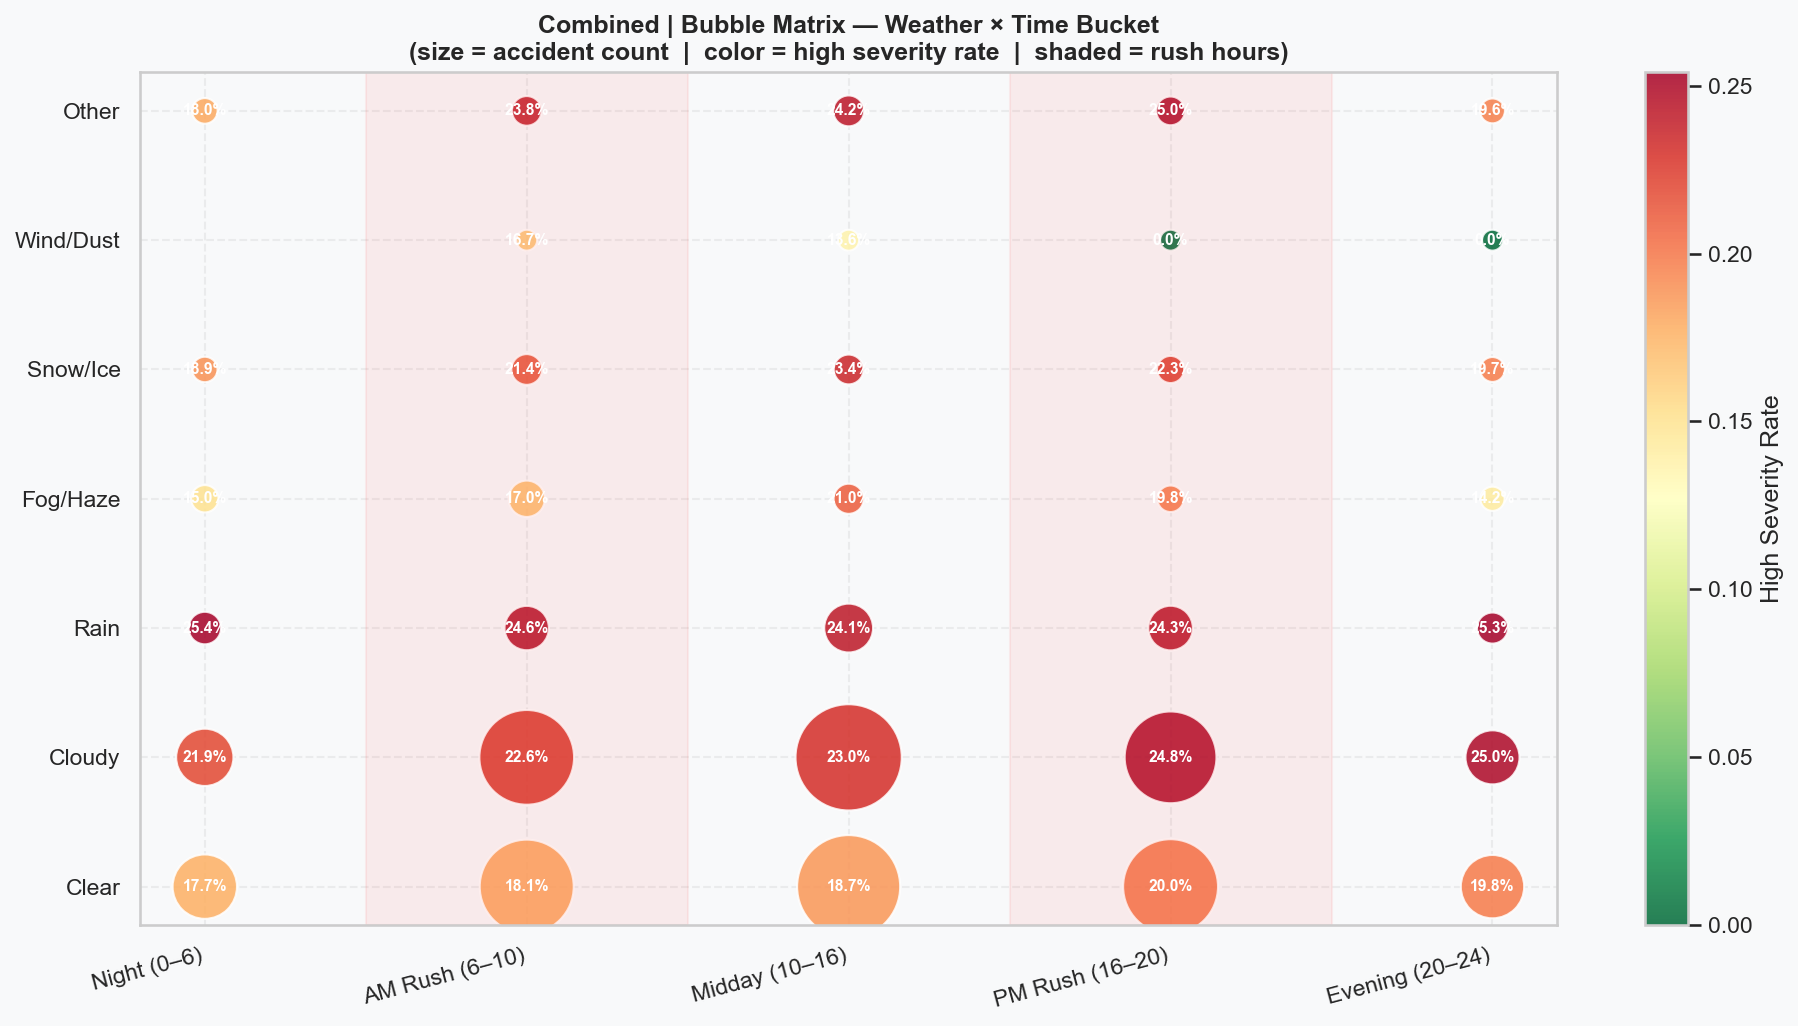

In [16]:
cross = df.groupby(['Weather_Group','Time_Bucket']).agg(
    Count=('ID','count'),
    High_Sev_Rate=('Is_High_Sev','mean')
).reset_index()
cross = cross[cross['Weather_Group'].isin(WEATHER_ORDER)]
cross = cross[cross['Time_Bucket'].isin(BUCKET_ORDER)]

wx = {w: i for i, w in enumerate(WEATHER_ORDER)}
bx = {b: i for i, b in enumerate(BUCKET_ORDER)}
cross['wx'] = cross['Weather_Group'].map(wx)
cross['bx'] = cross['Time_Bucket'].map(bx)

norm  = mcolors.Normalize(vmin=cross['High_Sev_Rate'].min(),
                           vmax=cross['High_Sev_Rate'].max())
sizes = (cross['Count'] / cross['Count'].max()) * 2500 + 100

fig, ax = plt.subplots(figsize=(13, 7))
fig.patch.set_facecolor(CLR_BG); ax.set_facecolor(CLR_BG)

sc = ax.scatter(cross['bx'], cross['wx'],
                s=sizes, c=cross['High_Sev_Rate'],
                cmap='RdYlGn_r', norm=norm,
                alpha=0.85, edgecolors='white', linewidth=1)

for _, row in cross.iterrows():
    ax.text(row['bx'], row['wx'],
            f"{row['High_Sev_Rate']*100:.1f}%",
            ha='center', va='center', fontsize=7.5,
            color='white', fontweight='bold')

ax.set_xticks(range(len(BUCKET_ORDER)))
ax.set_xticklabels(BUCKET_ORDER, rotation=15, ha='right')
ax.set_yticks(range(len(WEATHER_ORDER)))
ax.set_yticklabels(WEATHER_ORDER)
plt.colorbar(sc, ax=ax, label='High Severity Rate')

# highlight rush hour columns
for bi, bucket in enumerate(BUCKET_ORDER):
    if 'Rush' in bucket:
        ax.axvspan(bi-0.5, bi+0.5, alpha=0.06, color='red')

ax.set_title('Combined | Bubble Matrix — Weather × Time Bucket\n'
             '(size = accident count  |  color = high severity rate  |  shaded = rush hours)')
ax.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
save('chart_C1_bubble_matrix'); plt.show()

### Chart C-2 | Faceted Bar — Top 8 States: Severity Rate by Weather Group

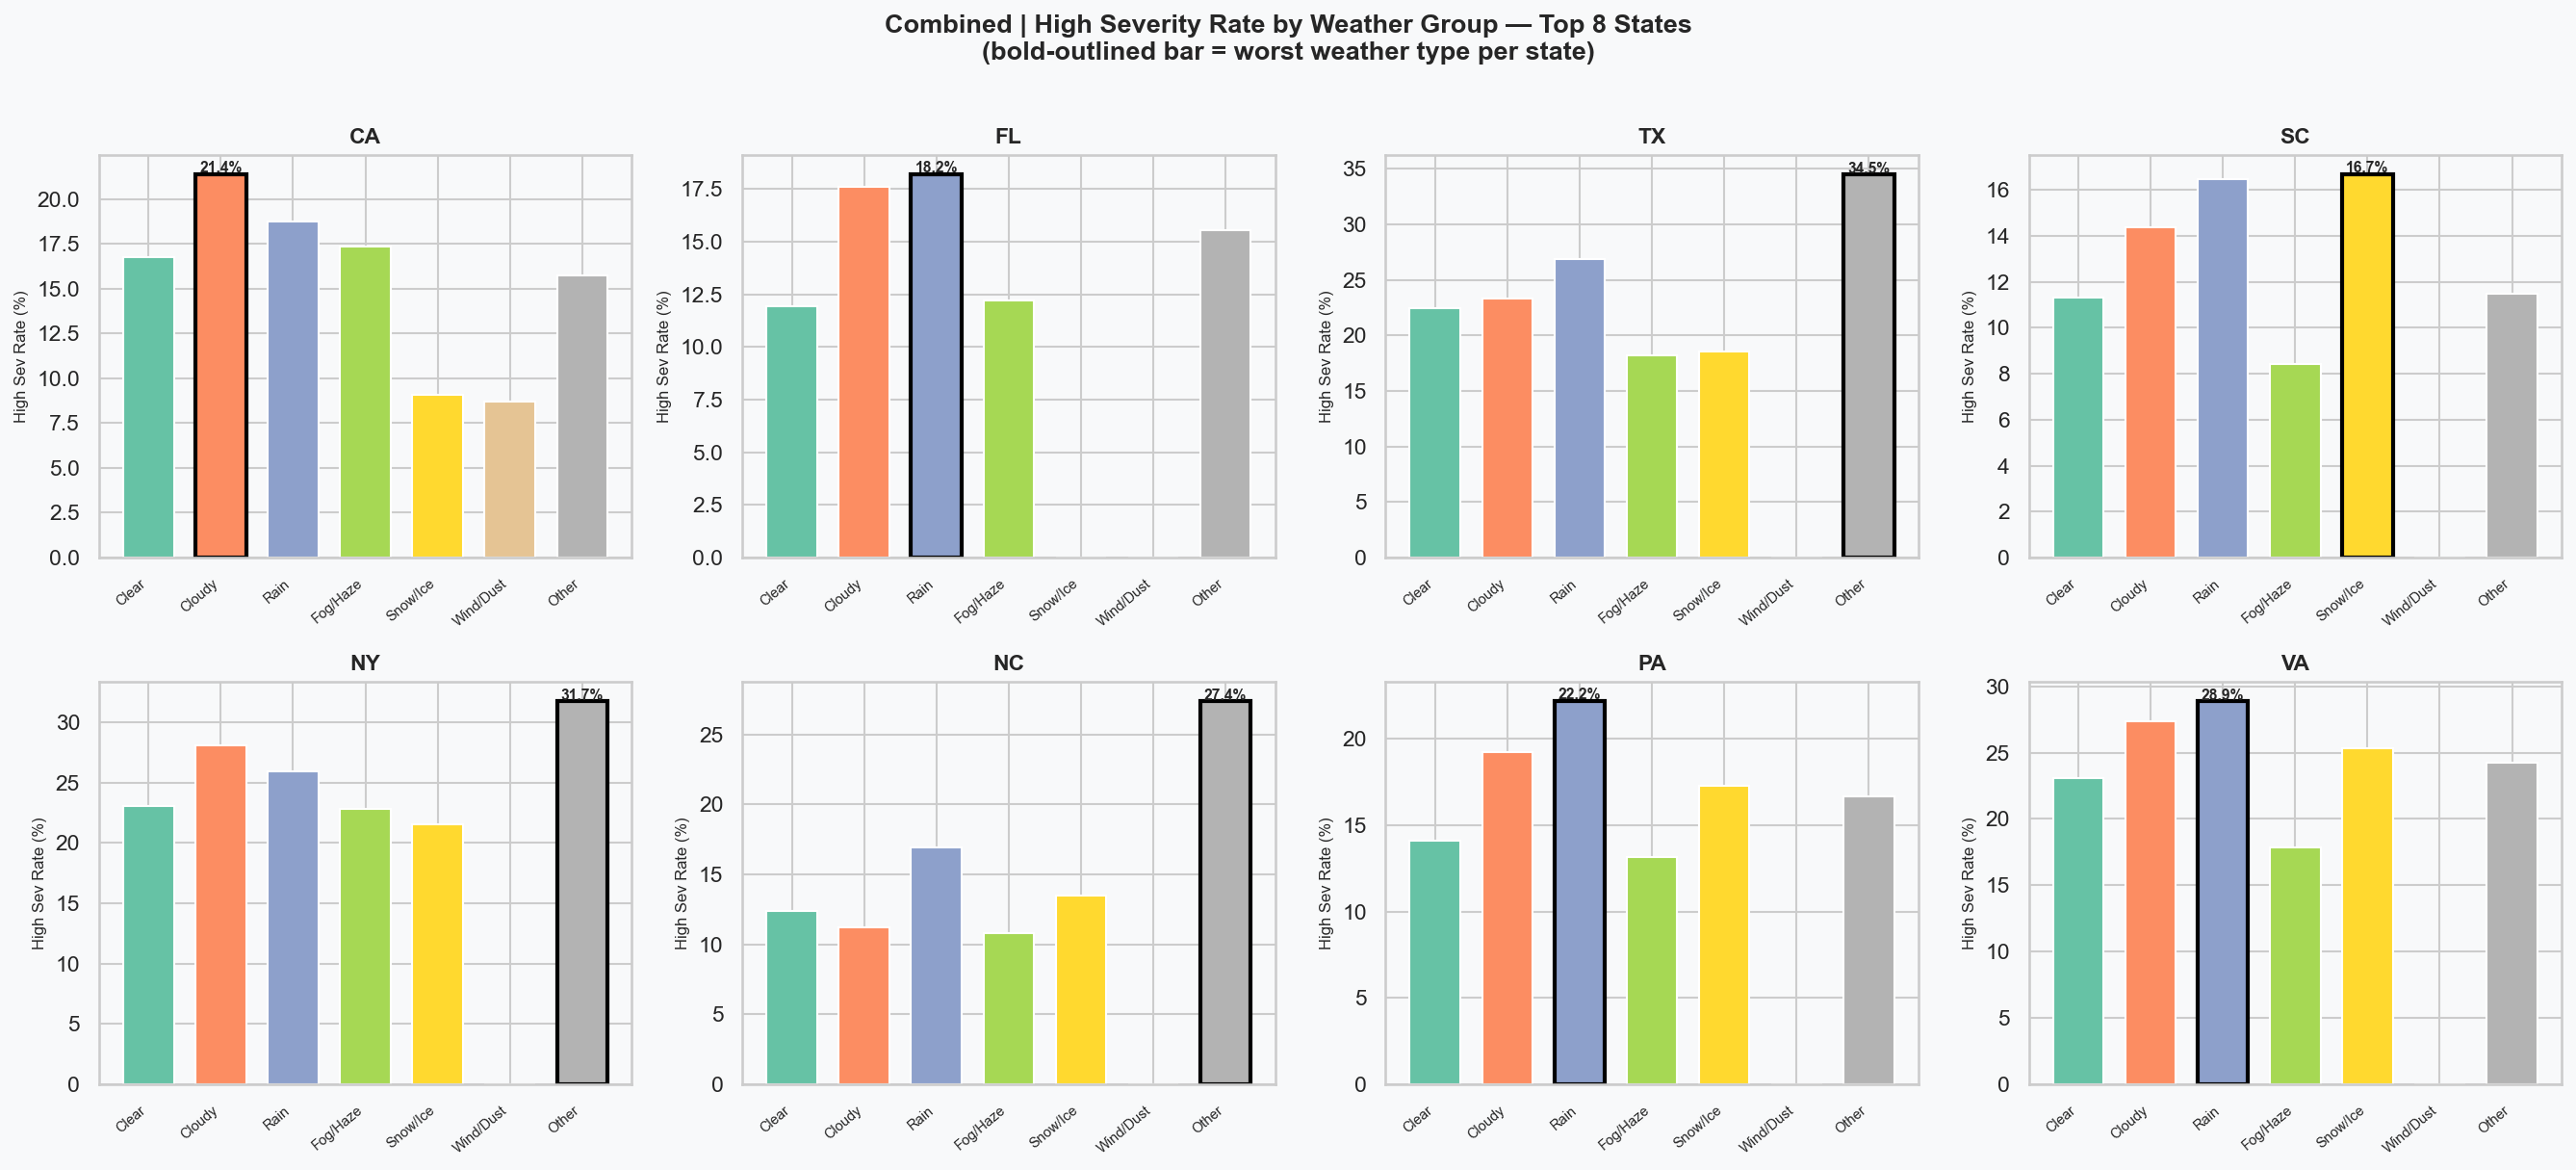

In [17]:
top8_states = df.groupby('State').size().nlargest(8).index.tolist()
facet_df = df[df['State'].isin(top8_states)]

state_wg = facet_df.groupby(['State','Weather_Group'])['Is_High_Sev'].mean()*100
state_wg = state_wg.unstack(fill_value=0).reindex(columns=WEATHER_ORDER, fill_value=0)
state_wg = state_wg.reindex(top8_states)

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=False)
fig.patch.set_facecolor(CLR_BG)
cmap_wg = plt.cm.get_cmap('Set2', len(WEATHER_ORDER))

for ax, state in zip(axes.flatten(), top8_states):
    ax.set_facecolor(CLR_BG)
    row = state_wg.loc[state]
    colors = [cmap_wg(i) for i in range(len(row))]
    bars = ax.bar(range(len(row)), row.values, color=colors, edgecolor='white', width=0.7)
    ax.set_xticks(range(len(row)))
    ax.set_xticklabels(WEATHER_ORDER, rotation=40, ha='right', fontsize=7)
    ax.set_title(state, fontsize=11, fontweight='bold')
    ax.set_ylabel('High Sev Rate (%)', fontsize=8)
    # highlight max
    max_idx = row.values.argmax()
    bars[max_idx].set_edgecolor('black')
    bars[max_idx].set_linewidth(2)
    ax.annotate(f'{row.values[max_idx]:.1f}%',
                (max_idx, row.values[max_idx]+0.1),
                ha='center', fontsize=7.5, fontweight='bold')

fig.suptitle('Combined | High Severity Rate by Weather Group — Top 8 States\n'
             '(bold-outlined bar = worst weather type per state)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
save('chart_C2_faceted_states'); plt.show()

---
## Statistical Validation

In [18]:
print('='*60)
print('  STATISTICAL VALIDATION')
print('='*60)

# H1 — Chi² Weather × Severity
ct1 = pd.crosstab(df['Weather_Group'], df['Is_High_Sev'])
chi2_h1, p_h1, _, _ = stats.chi2_contingency(ct1)
print(f'\nH1 — Chi² (Weather Group × High Severity)')
print(f'   χ² = {chi2_h1:.2f},   p = {p_h1:.2e}   {"✓ SIGNIFICANT" if p_h1<0.05 else "✗ not significant"}')

# H1 — Kruskal-Wallis on Visibility across weather groups
groups_vis = [df[df['Weather_Group']==w]['Visibility(mi)'].dropna().values
              for w in WEATHER_ORDER if w in df['Weather_Group'].unique()]
kw_stat, kw_p = stats.kruskal(*groups_vis)
print(f'\nH1 — Kruskal-Wallis (Visibility across weather groups)')
print(f'   H = {kw_stat:.2f},   p = {kw_p:.2e}   {"✓ SIGNIFICANT" if kw_p<0.05 else "✗ not significant"}')

# H1 — Visibility means per group
print('\n   Avg Visibility (mi) by Weather Group:')
vis_means = df.groupby('Weather_Group')['Visibility(mi)'].mean().reindex(WEATHER_ORDER)
for wg, v in vis_means.dropna().items():
    print(f'   {wg:<12} {v:.2f}')

# H2 — Chi² Rush Hour × Severity
ct2 = pd.crosstab(df['Is_Rush_Hour'], df['Is_High_Sev'])
chi2_h2, p_h2, _, _ = stats.chi2_contingency(ct2)
print(f'\nH2 — Chi² (Rush Hour × High Severity)')
print(f'   χ² = {chi2_h2:.2f},   p = {p_h2:.2e}   {"✓ SIGNIFICANT" if p_h2<0.05 else "✗ not significant"}')

# H2 — Duration difference
rush_dur    = df[(df['Is_Rush_Hour']==True) & df['Duration_Min'].notna()]['Duration_Min']
nonrush_dur = df[(df['Is_Rush_Hour']==False)& df['Duration_Min'].notna()]['Duration_Min']
t_dur, p_dur = stats.ttest_ind(rush_dur, nonrush_dur, equal_var=False)
print(f'\nH2 — t-test (Duration: Rush vs Non-Rush)')
print(f'   Rush avg duration    : {rush_dur.mean():.1f} min')
print(f'   Non-Rush avg duration: {nonrush_dur.mean():.1f} min')
print(f'   t = {t_dur:.2f},   p = {p_dur:.2e}   {"✓ SIGNIFICANT" if p_dur<0.05 else "✗ not significant"}')

# H2 — Severity by time bucket
print('\n   High Severity Rate (%) by Time Bucket:')
for b in BUCKET_ORDER:
    r = df[df['Time_Bucket']==b]['Is_High_Sev'].mean()*100
    tag = ' ← RUSH' if 'Rush' in b else ''
    print(f'   {b:<22} {r:.2f}%{tag}')

print('\n' + '='*60)
print(f'  Charts saved to current directory' if SAVE_FIGS else '  (SAVE_FIGS=False)')
print('='*60)

  STATISTICAL VALIDATION

H1 — Chi² (Weather Group × High Severity)
   χ² = 1509.29,   p = 0.00e+00   ✓ SIGNIFICANT

H1 — Kruskal-Wallis (Visibility across weather groups)
   H = 184832.56,   p = 0.00e+00   ✓ SIGNIFICANT

   Avg Visibility (mi) by Weather Group:
   Clear        9.85
   Cloudy       9.57
   Rain         6.14
   Fog/Haze     3.09
   Snow/Ice     2.81
   Wind/Dust    6.84
   Other        9.86

H2 — Chi² (Rush Hour × High Severity)
   χ² = 12.96,   p = 3.19e-04   ✓ SIGNIFICANT

H2 — t-test (Duration: Rush vs Non-Rush)
   Rush avg duration    : 98.1 min
   Non-Rush avg duration: 124.7 min
   t = -60.13,   p = 0.00e+00   ✓ SIGNIFICANT

   High Severity Rate (%) by Time Bucket:
   Night (0–6)            19.74%
   AM Rush (6–10)         20.64% ← RUSH
   Midday (10–16)         21.30%
   PM Rush (16–20)        22.49% ← RUSH
   Evening (20–24)        21.90%

  Charts saved to current directory
